# Чекпойнт 2. Разведочный анализ данных (EDA)

**Проект:** AutoML для временных рядов с использованием глубокого обучения  
**Домен:** финансовые временные ряды / прогнозирование криптовалют  
**Автор:** Курлянд Тимофей Александрович  
**Куратор:** Дмитрий Янышев

## Постановка задачи

Система должна на основе истории OHLCV прогнозировать поведение цены и формировать торговое решение:
`LONG` / `SHORT` / `NO TRADE`, а также уровни `TP`/`SL`.

Поэтому в EDA изучаются не только сырые свечи, но и:
- инженерные признаки без утечки будущего;
- целевая переменная triple-barrier;
- практическая применимость: комиссии, дисбаланс классов, разрывы биржи, аугментации.

Анализ выполнен одновременно по требованиям **ML-трека** и **DL-трека**.


In [1]:
from __future__ import annotations

import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import classification_report, confusion_matrix
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.tools.sm_exceptions import InterpolationWarning
from statsmodels.tsa.stattools import acf, adfuller, kpss

from automl_dl.features import add_market_features
from automl_dl.labels import triple_barrier_labels

warnings.simplefilter("ignore", InterpolationWarning)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (14, 6)
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.titlesize"] = 13

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "data").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
DATA_ROOT = PROJECT_ROOT / "data" / "raw"
SYMBOLS = ["BTC-USDT", "ETH-USDT", "BNB-USDT", "SOL-USDT"]
DISPLAY = {symbol: symbol.replace("-", "/") for symbol in SYMBOLS}
LABEL_NAMES = {-1: "SHORT", 0: "NO TRADE", 1: "LONG"}
print(PROJECT_ROOT)
print(DATA_ROOT)

D:\year_project
D:\year_project\data\raw


## 1. Загрузка данных и формирование рабочего датасета

Минутные свечи слишком детальны для всех графиков сразу, поэтому:
1. качество и стационарность проверяются на полном минутном ряде;
2. связи признаков с таргетом изучаются на `1h`-датасете с causal-признаками и triple-barrier разметкой;
3. для `pairplot` используется стратифицированная выборка, иначе диаграмма нечитаема.


In [2]:
raw = {}
for symbol in SYMBOLS:
    frame = pd.read_parquet(DATA_ROOT / symbol / "1m.parquet").sort_index()
    frame.index = pd.to_datetime(frame.index, utc=True)
    frame["symbol"] = DISPLAY[symbol]
    raw[symbol] = frame

hourly = {}
datasets = []
for symbol, minute in raw.items():
    hour = pd.read_parquet(DATA_ROOT / symbol / "1h.parquet").sort_index()
    hour.index = pd.to_datetime(hour.index, utc=True)
    featured = add_market_features(hour, volatility_window=24)
    labels = triple_barrier_labels(
        featured,
        horizon=24,
        take_profit_atr=2.0,
        stop_loss_atr=1.0,
    )
    table = pd.concat([featured, labels], axis=1)
    table["symbol"] = DISPLAY[symbol]
    table["hour_utc"] = table.index.hour
    table["weekday"] = table.index.dayofweek
    table["month"] = table.index.month
    table["abs_return"] = table["log_return"].abs()
    table["target_name"] = table["label"].map(LABEL_NAMES)
    hourly[symbol] = hour
    datasets.append(table)

dataset = pd.concat(datasets).sort_index()
model_frame = dataset.dropna(
    subset=[
        "log_return",
        "range_pct",
        "body_pct",
        "log_volume",
        "volume_change",
        "volatility",
        "atr_pct",
        "label",
        "mfe",
        "mae",
    ]
).copy()
model_frame["label"] = model_frame["label"].astype(int)

print("Минутные ряды:")
for symbol, frame in raw.items():
    print(f"  {DISPLAY[symbol]}: {len(frame):,} | {frame.index.min()} → {frame.index.max()}")
print(f"\nЧасовой размеченный датасет: {len(model_frame):,} строк")
display(model_frame["symbol"].value_counts().rename("rows").to_frame())

Минутные ряды:
  BTC/USDT: 3,065,538 | 2021-01-01 00:00:00+00:00 → 2026-10-31 14:10:00+00:00
  ETH/USDT: 3,065,538 | 2021-01-01 00:00:00+00:00 → 2026-10-31 14:10:00+00:00
  BNB/USDT: 3,065,539 | 2021-01-01 00:00:00+00:00 → 2026-10-31 14:11:00+00:00
  SOL/USDT: 3,065,538 | 2021-01-01 00:00:00+00:00 → 2026-10-31 14:11:00+00:00

Часовой размеченный датасет: 204,192 строк


,rows
symbol,
SOL/USDT,51048
ETH/USDT,51048
BNB/USDT,51048
BTC/USDT,51048


## 2. Основные статистики

Ниже `describe(include="all")` для рабочего ML-датасета. Категориальные признаки: `symbol`, `target_name`, календарные дискретизации. Вещественные: доходности, диапазон, объём, волатильность, экстремумы движения.


In [3]:
feature_view = model_frame[
    [
        "symbol",
        "target_name",
        "hour_utc",
        "weekday",
        "month",
        "open",
        "high",
        "low",
        "close",
        "volume",
        "log_return",
        "range_pct",
        "body_pct",
        "log_volume",
        "volume_change",
        "volatility",
        "atr_pct",
        "mfe",
        "mae",
        "exit_offset",
        "label",
    ]
].copy()

display(feature_view.describe(include="all").T)
print("\nТипы признаков:")
display(feature_view.dtypes.rename("dtype").to_frame())
print("\nЧисло уникальных значений категориальных признаков:")
display(
    feature_view[["symbol", "target_name", "hour_utc", "weekday", "month"]]
    .nunique()
    .rename("nunique")
    .to_frame()
)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
symbol,204192,4,SOL/USDT,51048,NaN,NaN,NaN,NaN,NaN,NaN,NaN
target_name,204192,3,SHORT,131668,NaN,NaN,NaN,NaN,NaN,NaN,NaN
hour_utc,204192.0,NaN,NaN,NaN,11.500392,6.922034,0.0,6.0,12.0,17.25,23.0
weekday,204192.0,NaN,NaN,NaN,2.999608,2.000201,0.0,1.0,3.0,5.0,6.0
month,204192.0,NaN,NaN,NaN,6.381562,3.388989,1.0,3.0,6.0,9.0,12.0
open,204192.0,NaN,NaN,NaN,15069.350535,28169.952345,1.7215,215.0,1108.925,7613.315,126011.18
high,204192.0,NaN,NaN,NaN,15126.778955,28264.773409,1.7725,215.9,1117.13,7660.0825,126199.63
low,204192.0,NaN,NaN,NaN,15009.362011,28071.22295,1.7116,214.2,1098.045,7541.9825,125252.74
close,204192.0,NaN,NaN,NaN,15069.593748,28170.26593,1.7215,215.0,1109.03,7613.63,126011.18
volume,204192.0,NaN,NaN,NaN,60470.475184,130540.304125,0.0,4055.09525,15044.25227,62291.839792,4974113.88



Типы признаков:


,dtype
symbol,str
target_name,str
hour_utc,int32
weekday,int32
month,int32
open,float64
high,float64
low,float64
close,float64
volume,float64



Число уникальных значений категориальных признаков:


,nunique
symbol,4
target_name,3
hour_utc,24
weekday,7
month,12


## 3. Пропущенные значения

### 3.1. Сырые OHLCV


In [4]:
missing_rows = []
for symbol, frame in raw.items():
    n = len(frame)
    for column in ["open", "high", "low", "close", "volume"]:
        n_missing = int(frame[column].isna().sum())
        missing_rows.append(
            {
                "пара": DISPLAY[symbol],
                "признак": column,
                "пропусков": n_missing,
                "доля": n_missing / n,
                "всего строк": n,
            }
        )
missing_raw = pd.DataFrame(missing_rows)
display(missing_raw.pivot(index="пара", columns="признак", values="пропусков"))
print("Максимальная доля пропусков в сырых OHLCV:", float(missing_raw["доля"].max()))

признак,close,high,low,open,volume
пара,,,,,
BNB/USDT,0,0,0,0,0
BTC/USDT,0,0,0,0,0
ETH/USDT,0,0,0,0,0
SOL/USDT,0,0,0,0,0


Максимальная доля пропусков в сырых OHLCV: 0.0


### 3.2. Инженерные признаки и таргет

Пропуски на старте ряда возникают из-за `diff()` и `rolling()` — это не ошибки источника, а следствие причинной инженерии признаков.


In [5]:
engineered_columns = [
    "log_return",
    "range_pct",
    "body_pct",
    "log_volume",
    "volume_change",
    "volatility",
    "atr",
    "atr_pct",
    "label",
    "exit_offset",
    "mfe",
    "mae",
]
missing_engineered = []
for symbol in SYMBOLS:
    table = dataset.loc[dataset["symbol"] == DISPLAY[symbol]]
    n = len(table)
    for column in engineered_columns:
        n_missing = int(table[column].isna().sum())
        missing_engineered.append(
            {
                "пара": DISPLAY[symbol],
                "признак": column,
                "пропусков": n_missing,
                "доля": n_missing / n,
            }
        )
missing_eng = pd.DataFrame(missing_engineered)
display(missing_eng.pivot(index="признак", columns="пара", values="доля").style.format("{:.2%}"))

sparsity = model_frame.isna().mean().sort_values(ascending=False)
print("\nРазреженность рабочего датасета после удаления warmup-пропусков:")
display(sparsity.rename("доля NaN").to_frame().style.format("{:.2%}"))
print("Средняя доля NaN по признакам рабочего датасета:", f"{sparsity.mean():.4%}")

пара,BNB/USDT,BTC/USDT,ETH/USDT,SOL/USDT
признак,,,,
atr,0.05%,0.05%,0.05%,0.05%
atr_pct,0.05%,0.05%,0.05%,0.05%
body_pct,0.00%,0.00%,0.00%,0.00%
exit_offset,0.09%,0.09%,0.09%,0.09%
label,0.09%,0.09%,0.09%,0.09%
log_return,0.00%,0.00%,0.00%,0.00%
log_volume,0.00%,0.00%,0.00%,0.00%
mae,0.09%,0.09%,0.09%,0.09%
mfe,0.09%,0.09%,0.09%,0.09%



Разреженность рабочего датасета после удаления warmup-пропусков:


,доля NaN
open,0.00%
high,0.00%
low,0.00%
close,0.00%
volume,0.00%
log_return,0.00%
range_pct,0.00%
body_pct,0.00%
log_volume,0.00%
volume_change,0.00%


Средняя доля NaN по признакам рабочего датасета: 0.0000%


**Гипотеза о пропусках.**

1. В сырых Binance OHLCV пропусков значений нет: биржа отдаёт заполненные свечи.
2. Разрывы временной сетки — это не `NaN`, а отсутствующие timestamps во время технических остановок.
3. `NaN` в признаках появляются только в начале ряда из-за лагов и rolling-окон.
4. `NaN` в `label/mfe/mae` появляются в хвосте ряда, где горизонт triple-barrier ещё не завершён.

**Обработка.**  
Warmup- и unfinished-horizon строки удаляются перед обучением. Биржевые разрывы не импутируются нулями или forward-fill цены: это исказило бы доходности. Вместо этого окна модели не должны пересекать разрыв.


In [6]:
gap_rows = []
for symbol, frame in raw.items():
    diffs = frame.index.to_series().diff()
    missing = diffs.div(pd.Timedelta(minutes=1)).sub(1).clip(lower=0).fillna(0)
    gap_rows.append(
        {
            "пара": DISPLAY[symbol],
            "разрывов": int((missing > 0).sum()),
            "пропущено минут": int(missing.sum()),
            "макс. разрыв, мин": int(missing.max()),
            "доля пропущенного времени": float(missing.sum() / (len(frame) + missing.sum())),
        }
    )
gaps = pd.DataFrame(gap_rows).set_index("пара")
display(gaps.style.format({"доля пропущенного времени": "{:.4%}"}))

,разрывов,пропущено минут,"макс. разрыв, мин",доля пропущенного времени
пара,,,,
BTC/USDT,7,1073,284,0.0350%
ETH/USDT,7,1073,284,0.0350%
BNB/USDT,7,1073,284,0.0350%
SOL/USDT,8,1074,284,0.0350%


## 4. Ошибочные значения и логические инварианты

Для OHLCV проверяются инварианты свечи и допустимость цен/объёмов.


In [7]:
error_rows = []
for symbol, frame in raw.items():
    bad_price = (frame[["open", "high", "low", "close"]] <= 0).any(axis=1)
    bad_ohlc = (
        (frame["high"] < frame[["open", "close", "low"]].max(axis=1))
        | (frame["low"] > frame[["open", "close", "high"]].min(axis=1))
        | (frame["high"] < frame["low"])
    )
    bad_volume = frame["volume"] < 0
    error_rows.append(
        {
            "пара": DISPLAY[symbol],
            "неположительные цены": int(bad_price.sum()),
            "нарушения OHLC": int(bad_ohlc.sum()),
            "отрицательный объём": int(bad_volume.sum()),
            "нулевой объём": int((frame["volume"] == 0).sum()),
        }
    )
errors = pd.DataFrame(error_rows).set_index("пара")
display(errors)

invalid_labels = sorted(set(model_frame["label"].unique()) - {-1, 0, 1})
print("Недопустимые классы таргета:", invalid_labels if invalid_labels else "нет")
assert errors[["неположительные цены", "нарушения OHLC", "отрицательный объём"]].to_numpy().sum() == 0
assert not invalid_labels
print("Критические логические ошибки не обнаружены.")

,неположительные цены,нарушения OHLC,отрицательный объём,нулевой объём
пара,,,,
BTC/USDT,0,0,0,161
ETH/USDT,0,0,0,161
BNB/USDT,0,0,0,160
SOL/USDT,0,0,0,750


Недопустимые классы таргета: нет
Критические логические ошибки не обнаружены.


**Обработка ошибочных значений.**  
Критических ошибок нет. Нулевой объём оставляем: это осмысленное состояние «сделок не было». Недопустимых классов triple-barrier нет — целевая переменная строго трёхклассовая.


## 5. Выбросы

В финансовых рядах «выброс» часто является информативным событием: ликвидация, новость, каскад стопов. Поэтому цель не удалить все экстремумы, а понять их природу.


,нижняя граница,верхняя граница,число выбросов,доля,min,max
признак,,,,,,
log_return,-0.034333,0.034474,1885,0.92%,-0.214234,0.170977
range_pct,-0.038351,0.057009,1609,0.79%,0.000000,0.409425
volume,-287128.627462,353475.562505,5996,2.94%,0.000000,4974113.880000
volatility,-0.020191,0.032904,1047,0.51%,0.000455,0.072164
mfe,-0.139525,0.185125,1657,0.81%,-0.000784,0.821427
mae,-0.188124,0.141839,1374,0.67%,-0.544353,0.001138


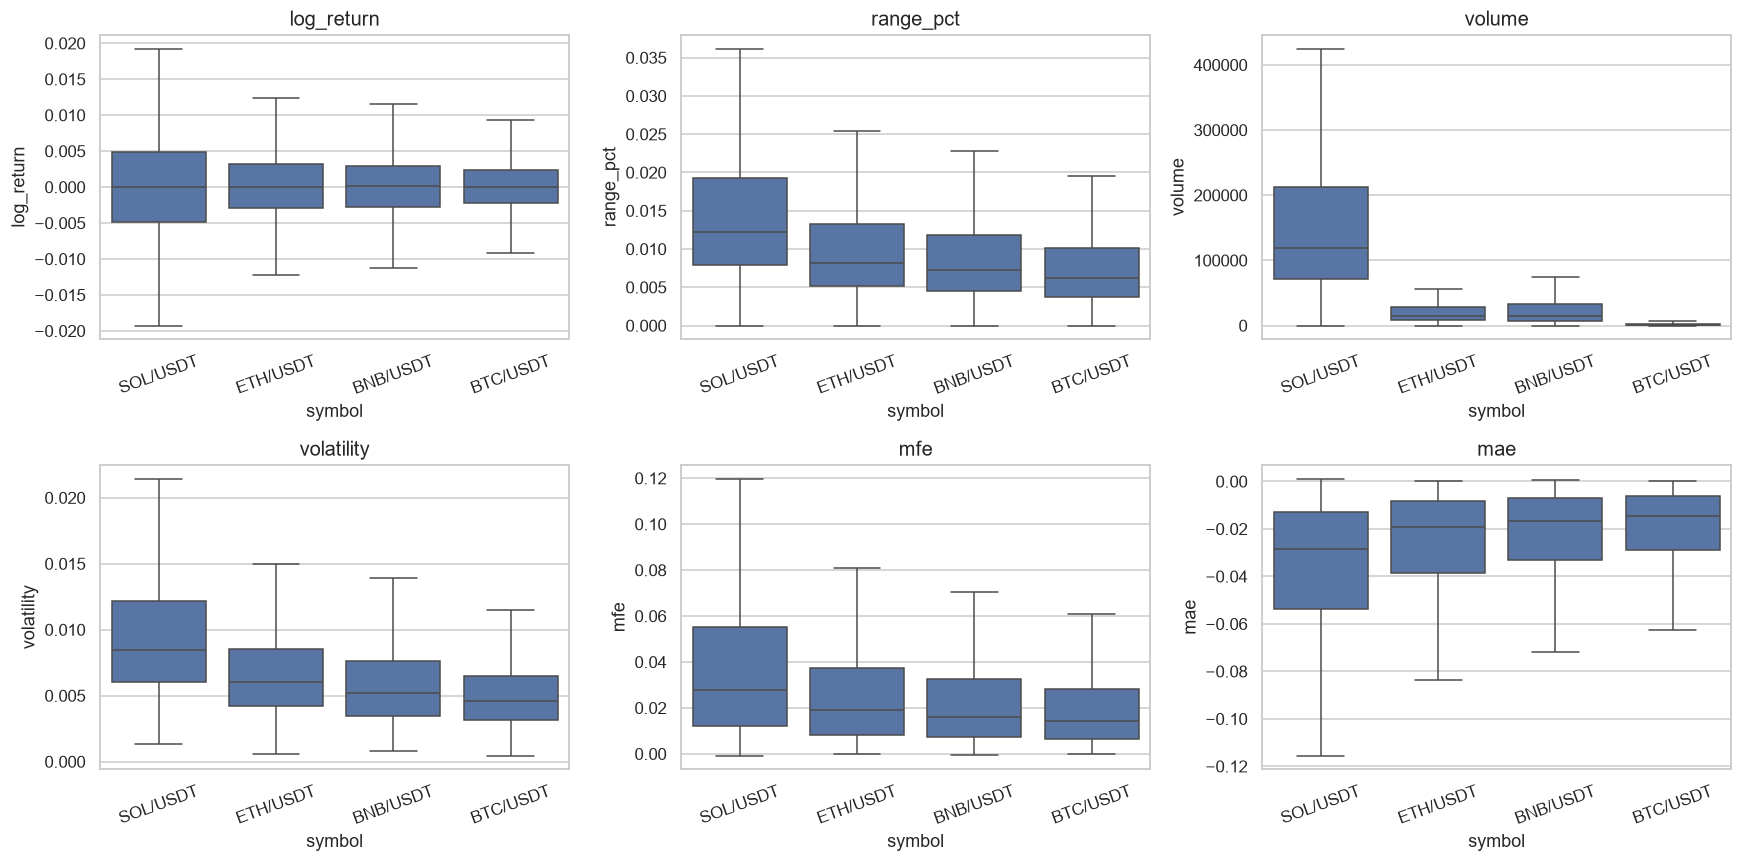

Примеры 0.1% самых экстремальных часовых доходностей:


,symbol,close,log_return,volume,volatility,target_name
timestamp,,,,,,
2021-05-19 12:00:00+00:00,SOL/USDT,35.4900,-0.214234,2.100417e+06,0.057865,SHORT
2022-05-11 12:00:00+00:00,SOL/USDT,49.5700,-0.213861,1.274851e+06,0.049433,LONG
2021-02-23 08:00:00+00:00,BNB/USDT,195.6062,-0.168726,1.640572e+06,0.050362,LONG
2021-09-07 14:00:00+00:00,SOL/USDT,152.2300,-0.167509,2.007651e+06,0.042645,NO TRADE
2021-05-19 12:00:00+00:00,BNB/USDT,335.5000,-0.162048,1.109787e+06,0.040624,SHORT
2021-09-07 14:00:00+00:00,BNB/USDT,401.9000,-0.153333,4.161717e+05,0.031801,NO TRADE
2021-02-20 00:00:00+00:00,BNB/USDT,288.4656,-0.143900,1.048258e+06,0.057119,SHORT
2021-05-19 12:00:00+00:00,ETH/USDT,2365.1800,-0.140175,4.374624e+05,0.033726,SHORT
2022-11-09 15:00:00+00:00,SOL/USDT,16.0700,-0.139735,1.804360e+06,0.053725,SHORT


,symbol,close,log_return,volume,volatility,target_name
timestamp,,,,,,
2022-11-09 22:00:00+00:00,SOL/USDT,14.2200,0.129721,1702817.410,0.061995,LONG
2022-05-11 13:00:00+00:00,SOL/USDT,56.7500,0.135270,1540784.770,0.058326,SHORT
2021-01-08 09:00:00+00:00,SOL/USDT,2.7279,0.136600,2463318.160,0.050989,LONG
2022-11-08 16:00:00+00:00,BNB/USDT,375.4000,0.138032,684057.261,0.031799,SHORT
2021-01-07 12:00:00+00:00,SOL/USDT,2.5402,0.142105,4039649.450,0.050735,SHORT
2021-01-08 12:00:00+00:00,SOL/USDT,3.6418,0.144473,3481259.940,0.053916,SHORT
2021-05-19 13:00:00+00:00,SOL/USDT,41.1420,0.147779,2188866.416,0.066432,SHORT
2022-11-14 06:00:00+00:00,SOL/USDT,14.5700,0.153236,1541884.020,0.037319,SHORT
2021-06-22 14:00:00+00:00,SOL/USDT,24.5030,0.154035,1513383.422,0.046389,LONG


In [8]:
def iqr_bounds(series: pd.Series, factor: float = 5.0):
    q1, q3 = series.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - factor * iqr, q3 + factor * iqr

outlier_rows = []
for column in ["log_return", "range_pct", "volume", "volatility", "mfe", "mae"]:
    series = model_frame[column].dropna()
    low, high = iqr_bounds(series)
    mask = (series < low) | (series > high)
    outlier_rows.append(
        {
            "признак": column,
            "нижняя граница": low,
            "верхняя граница": high,
            "число выбросов": int(mask.sum()),
            "доля": float(mask.mean()),
            "min": float(series.min()),
            "max": float(series.max()),
        }
    )
outliers = pd.DataFrame(outlier_rows).set_index("признак")
display(
    outliers.style.format(
        {
            "нижняя граница": "{:.6f}",
            "верхняя граница": "{:.6f}",
            "доля": "{:.2%}",
            "min": "{:.6f}",
            "max": "{:.6f}",
        }
    )
)

fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for axis, column in zip(
    axes.flat,
    ["log_return", "range_pct", "volume", "volatility", "mfe", "mae"],
    strict=True,
):
    sns.boxplot(data=model_frame, x="symbol", y=column, ax=axis, showfliers=False)
    axis.set_title(column)
    axis.tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.show()

extreme = model_frame.loc[
    model_frame["log_return"].abs() > model_frame["log_return"].abs().quantile(0.999),
    ["symbol", "close", "log_return", "volume", "volatility", "target_name"],
].sort_values("log_return")
print("Примеры 0.1% самых экстремальных часовых доходностей:")
display(extreme.head(10))
display(extreme.tail(10))

**Обработка выбросов.**  
Удалять хвостовые доходности нельзя: именно они определяют риск стратегии и калибровку `TP/SL`. Практическая обработка:
- для обучения использовать robust/quantile loss;
- клиппинг признаков объёма/диапазона допустим только во входных фичах, не в таргете;
- экстремальные эпизоды сохраняются в отдельном stress-test наборе.


## 6. Поведение признаков по отдельности

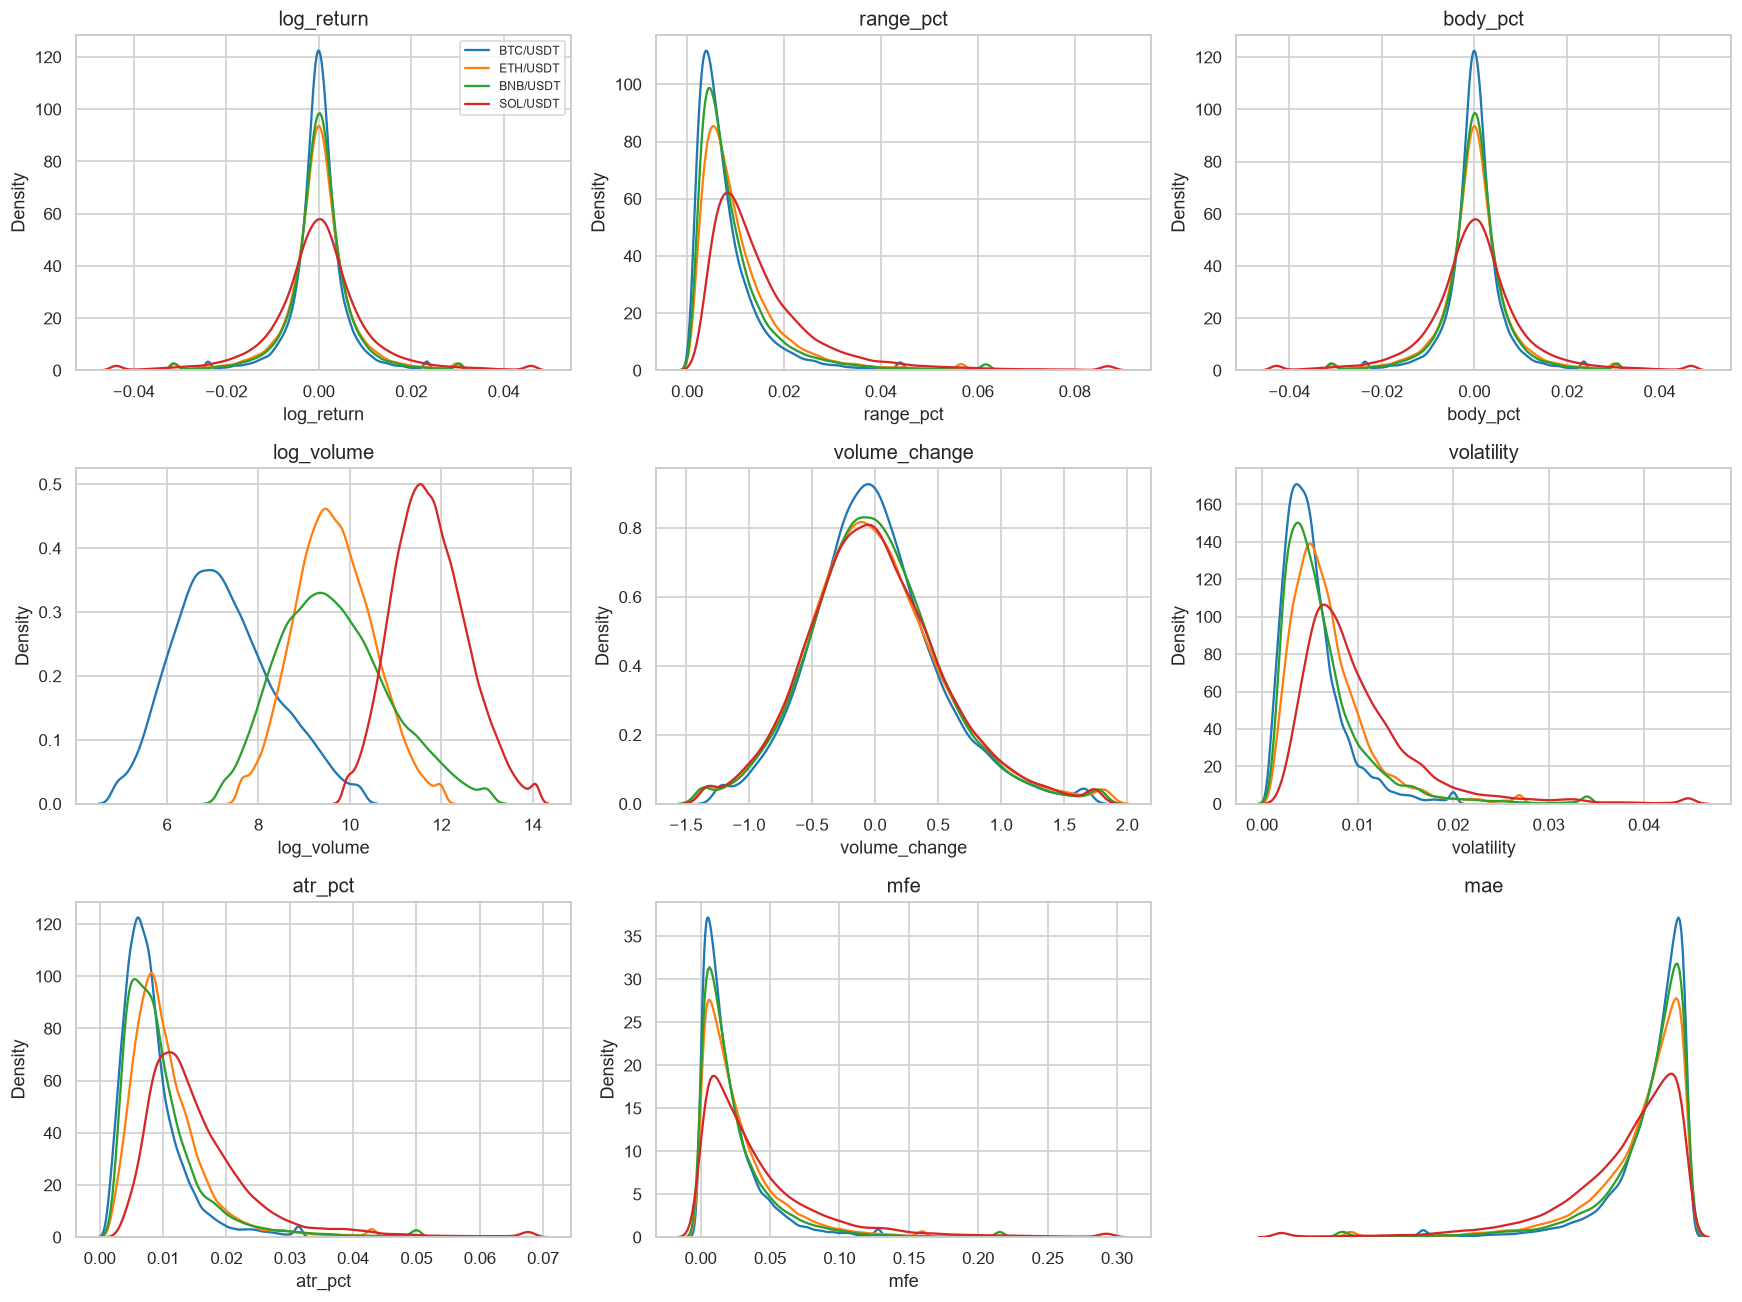

In [9]:
numeric_features = [
    "log_return",
    "range_pct",
    "body_pct",
    "log_volume",
    "volume_change",
    "volatility",
    "atr_pct",
]
fig, axes = plt.subplots(3, 3, figsize=(16, 12))
plot_columns = numeric_features + ["mfe", "mae"]
for axis, column in zip(axes.flat, plot_columns, strict=False):
    for symbol, color in zip(SYMBOLS, sns.color_palette("tab10", len(SYMBOLS)), strict=True):
        series = model_frame.loc[model_frame["symbol"] == DISPLAY[symbol], column].dropna()
        lower, upper = series.quantile([0.005, 0.995])
        sns.kdeplot(series.clip(lower, upper), ax=axis, label=DISPLAY[symbol], color=color)
    axis.set_title(column)
axes.flat[-1].axis("off")
axes.flat[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

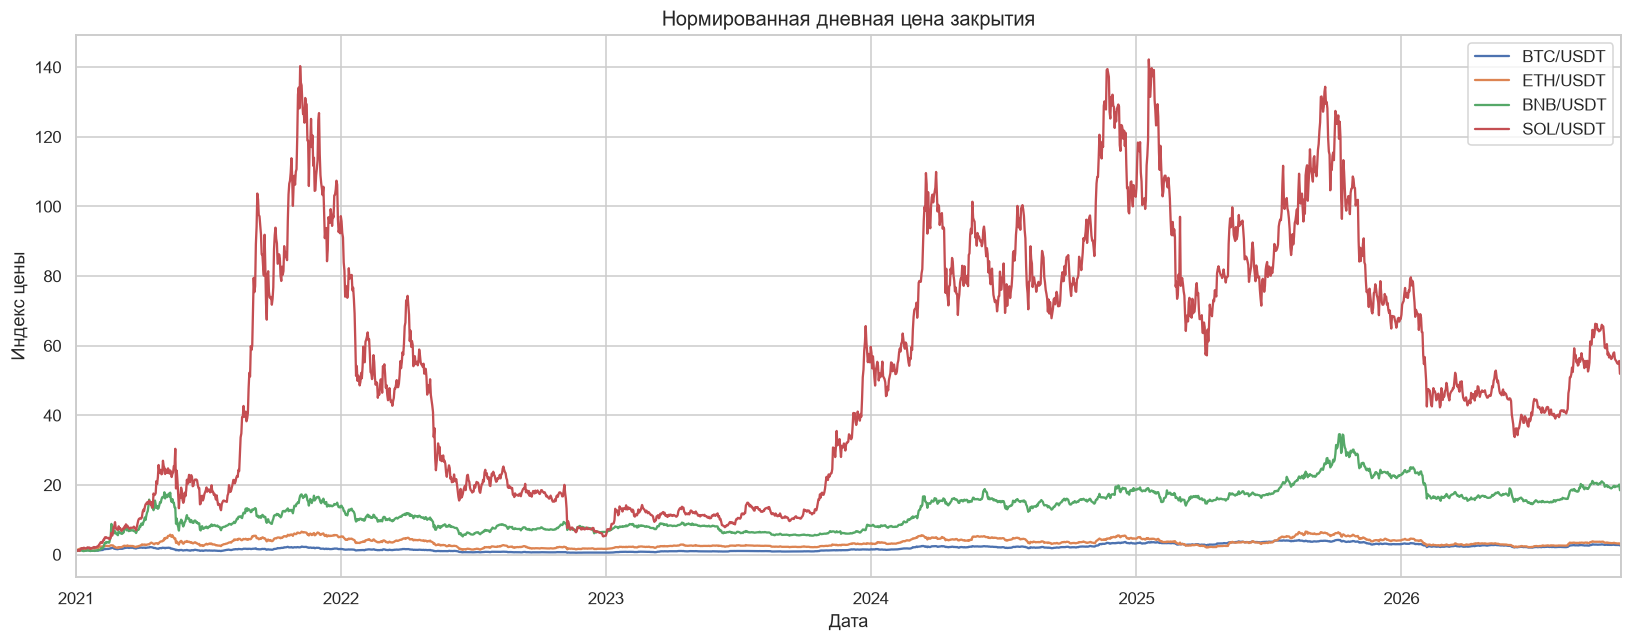

,изменение за период
BTC/USDT,164.37%
ETH/USDT,208.94%
BNB/USDT,1764.53%
SOL/USDT,5101.13%


In [10]:
daily_close = pd.concat(
    {DISPLAY[symbol]: hourly[symbol]["close"].resample("1D").last() for symbol in SYMBOLS},
    axis=1,
).dropna()
normalized = daily_close / daily_close.iloc[0]
normalized.plot(figsize=(15, 6), linewidth=1.5)
plt.title("Нормированная дневная цена закрытия")
plt.ylabel("Индекс цены")
plt.xlabel("Дата")
plt.tight_layout()
plt.show()
display(
    (daily_close.iloc[-1] / daily_close.iloc[0] - 1)
    .rename("изменение за период")
    .to_frame()
    .style.format("{:.2%}")
)

## 7. Целевая переменная, баланс классов и связь признаков с таргетом

target_name,LONG,NO TRADE,SHORT
symbol,,,
BNB/USDT,31.31%,4.08%,64.60%
BTC/USDT,30.50%,5.75%,63.75%
ETH/USDT,31.40%,4.50%,64.10%
SOL/USDT,31.06%,3.46%,65.48%


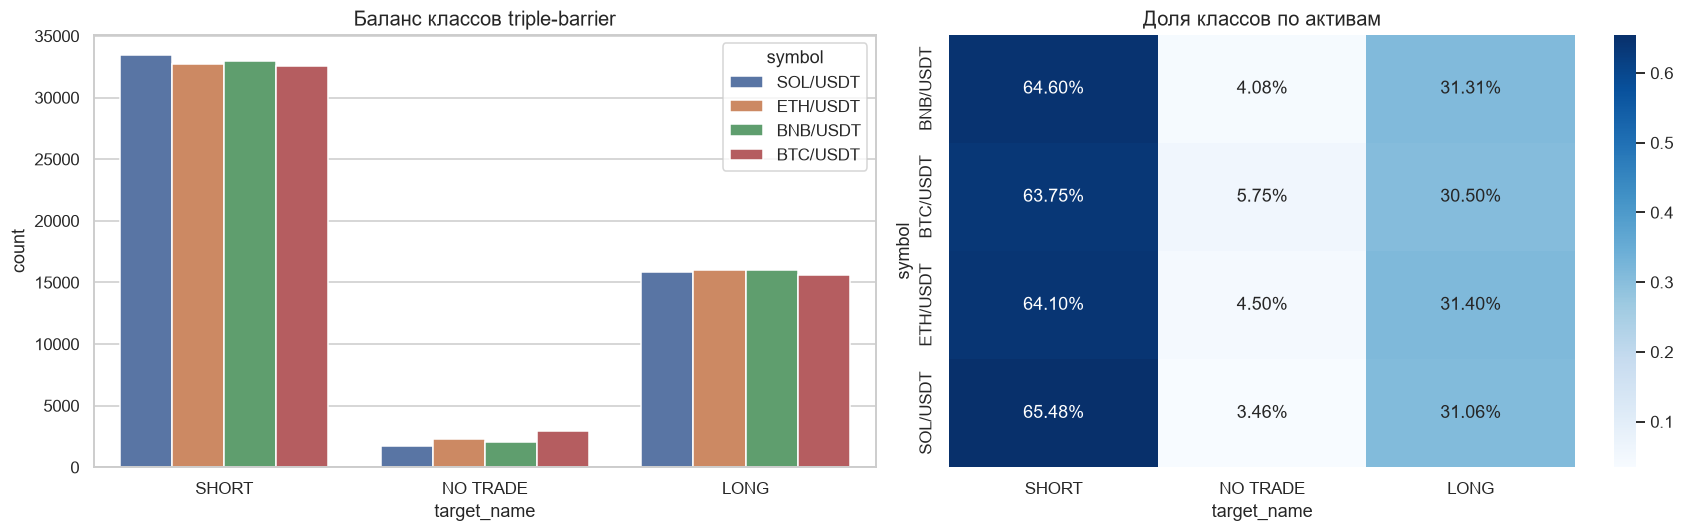

In [11]:
balance = (
    model_frame.groupby(["symbol", "target_name"]).size().rename("count").reset_index()
)
balance["share"] = balance.groupby("symbol")["count"].transform(lambda values: values / values.sum())
display(balance.pivot(index="symbol", columns="target_name", values="share").style.format("{:.2%}"))

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
sns.countplot(
    data=model_frame,
    x="target_name",
    hue="symbol",
    ax=axes[0],
    order=["SHORT", "NO TRADE", "LONG"],
)
axes[0].set_title("Баланс классов triple-barrier")
sns.heatmap(
    balance.pivot(index="symbol", columns="target_name", values="share")[
        ["SHORT", "NO TRADE", "LONG"]
    ],
    annot=True,
    fmt=".2%",
    cmap="Blues",
    ax=axes[1],
)
axes[1].set_title("Доля классов по активам")
plt.tight_layout()
plt.show()

,log_return,range_pct,body_pct,log_volume,volume_change,volatility,atr_pct,mfe,mae,exit_offset
target_name,,,,,,,,,,
LONG,0.00011,0.01130,0.00014,9.58494,0.00365,0.00714,0.01115,0.05048,-0.01213,7.47380
NO TRADE,0.00022,0.01063,0.00025,9.19575,-0.04401,0.00825,0.01260,0.02107,-0.01008,22.18201
SHORT,-0.00000,0.01120,0.00003,9.59652,0.00127,0.00711,0.01112,0.02001,-0.03902,5.08770


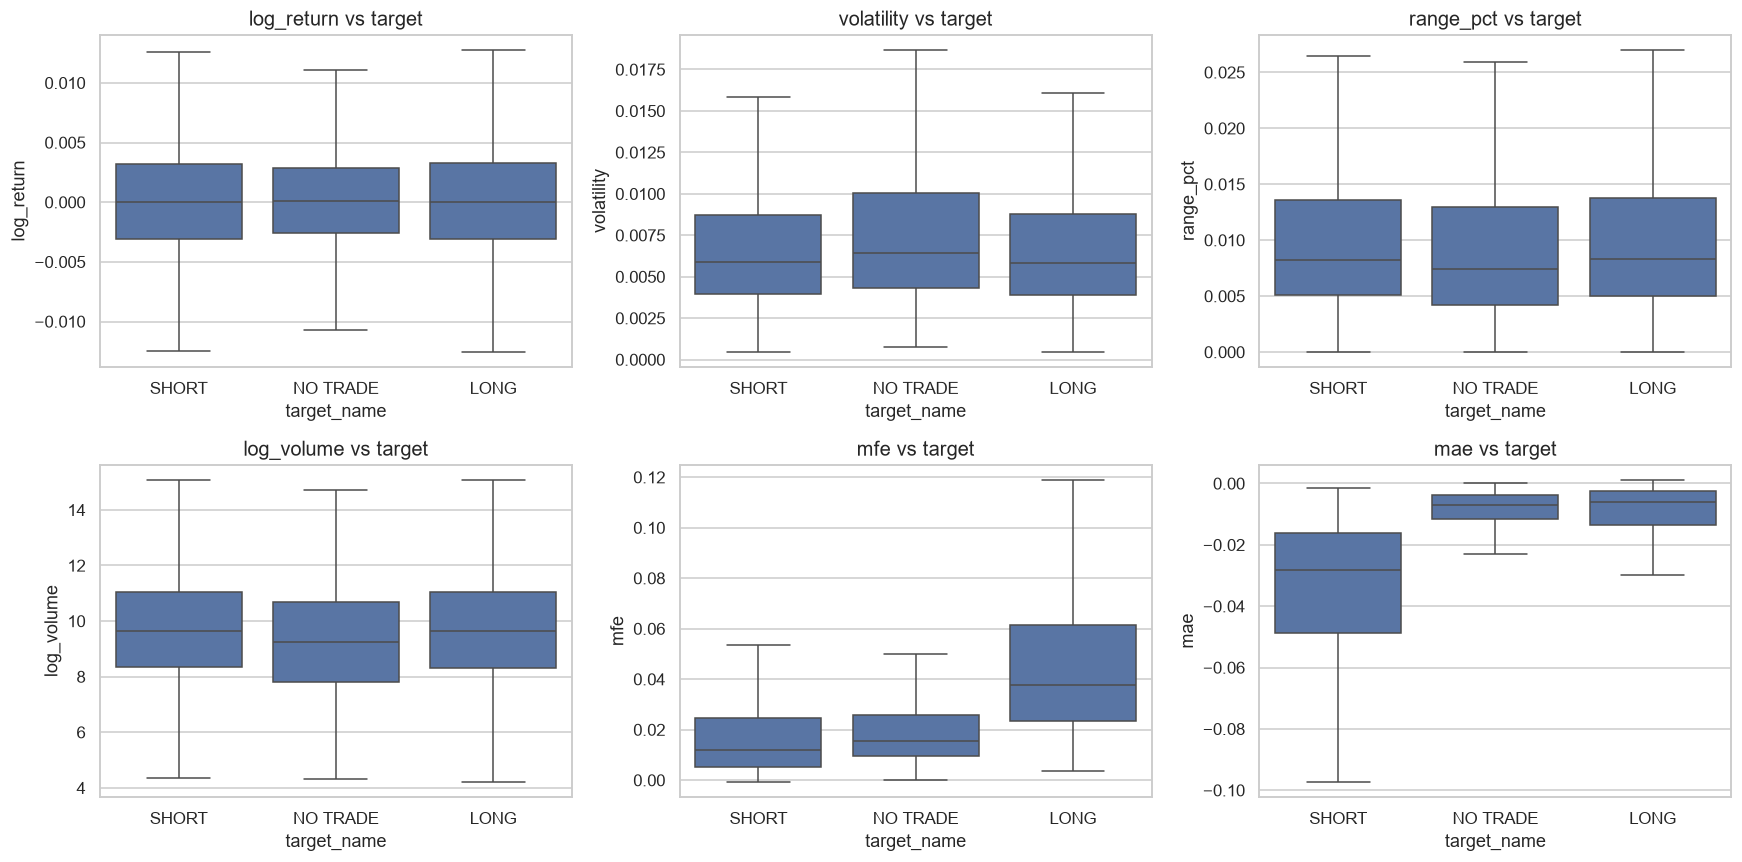

In [12]:
target_means = model_frame.groupby("target_name")[numeric_features + ["mfe", "mae", "exit_offset"]].mean()
display(target_means.style.background_gradient(cmap="vlag", axis=0).format("{:.5f}"))

fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for axis, column in zip(
    axes.flat,
    ["log_return", "volatility", "range_pct", "log_volume", "mfe", "mae"],
    strict=True,
):
    sns.boxplot(
        data=model_frame,
        x="target_name",
        y=column,
        order=["SHORT", "NO TRADE", "LONG"],
        showfliers=False,
        ax=axis,
    )
    axis.set_title(f"{column} vs target")
plt.tight_layout()
plt.show()

## 8. Попарные корреляции и pairplot

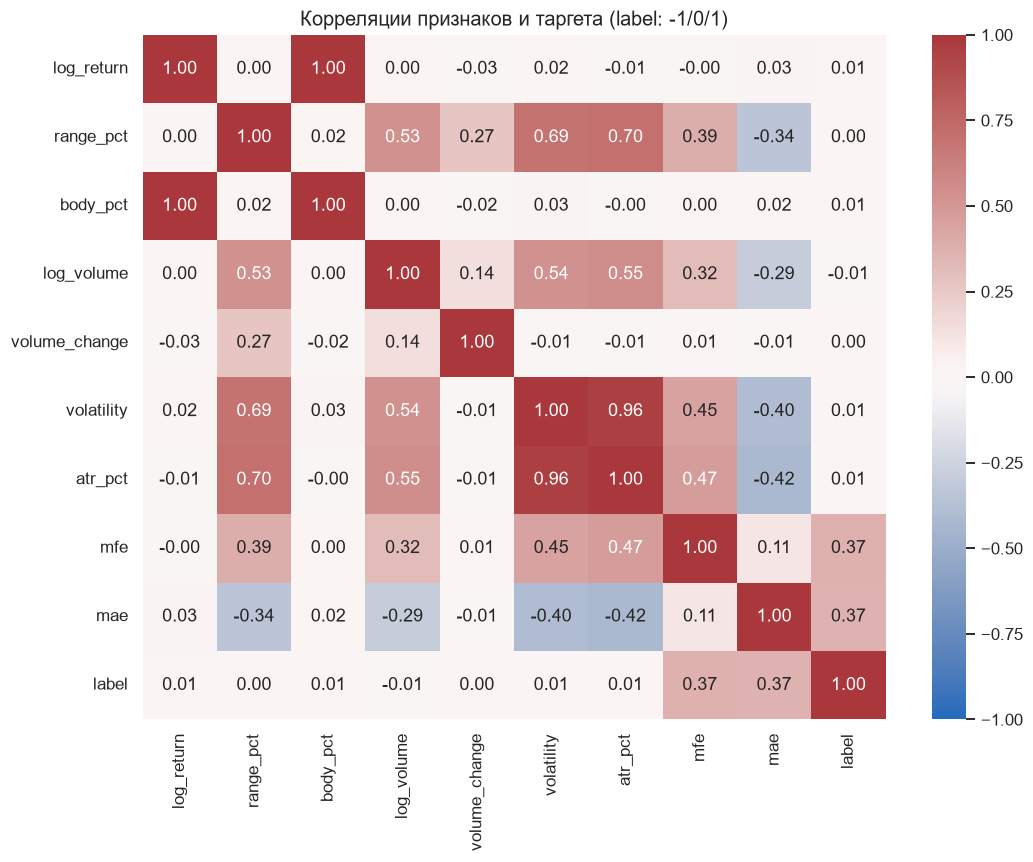

,corr_with_label
mfe,+0.3720
mae,+0.3662
log_volume,-0.0062
body_pct,+0.0061
log_return,+0.0060
volatility,+0.0058
atr_pct,+0.0051
range_pct,+0.0032
volume_change,+0.0006


In [13]:
corr_features = numeric_features + ["mfe", "mae", "label"]
corr = model_frame[corr_features].corr()
plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="vlag", center=0, vmin=-1, vmax=1)
plt.title("Корреляции признаков и таргета (label: -1/0/1)")
plt.tight_layout()
plt.show()

target_corr = corr["label"].drop("label").sort_values(key=np.abs, ascending=False)
display(target_corr.rename("corr_with_label").to_frame().style.format("{:+.4f}"))

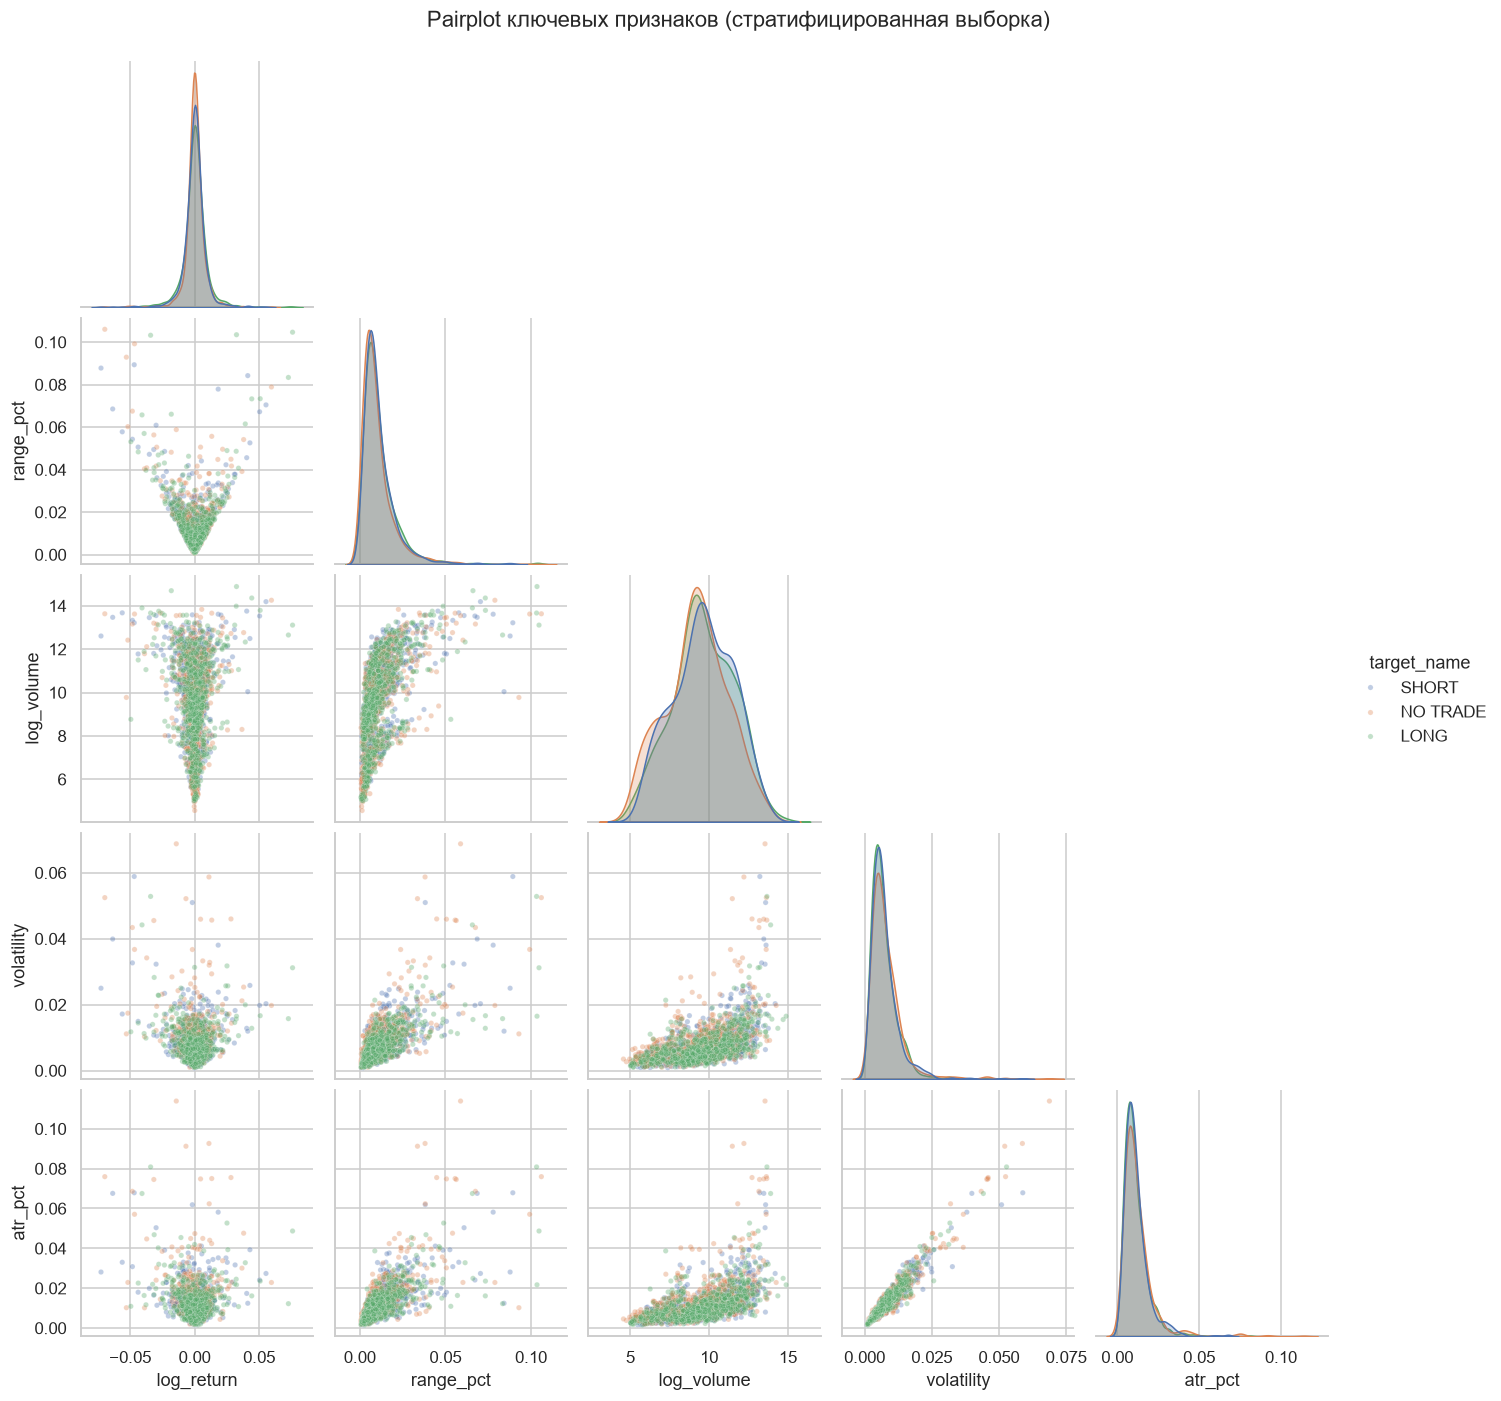

In [14]:
pair_cols = ["log_return", "range_pct", "log_volume", "volatility", "atr_pct", "label"]
pair_sample = (
    model_frame[pair_cols + ["target_name"]]
    .groupby("label", group_keys=False)
    .apply(lambda group: group.sample(n=min(len(group), 800), random_state=42))
)
sns.pairplot(
    pair_sample,
    vars=["log_return", "range_pct", "log_volume", "volatility", "atr_pct"],
    hue="target_name",
    corner=True,
    plot_kws={"alpha": 0.35, "s": 12},
    diag_kind="kde",
)
plt.suptitle("Pairplot ключевых признаков (стратифицированная выборка)", y=1.02)
plt.show()

## 9. Сводные таблицы и доменные визуализации

target_name,LONG,NO TRADE,SHORT
hour_utc,,,
0,31.27%,4.55%,64.18%
1,31.95%,4.46%,63.58%
2,32.51%,4.51%,62.99%
3,32.46%,4.55%,62.99%
4,31.82%,4.37%,63.81%
5,31.24%,4.69%,64.06%
6,30.70%,4.72%,64.57%
7,31.42%,4.69%,63.89%
8,30.62%,4.48%,64.90%


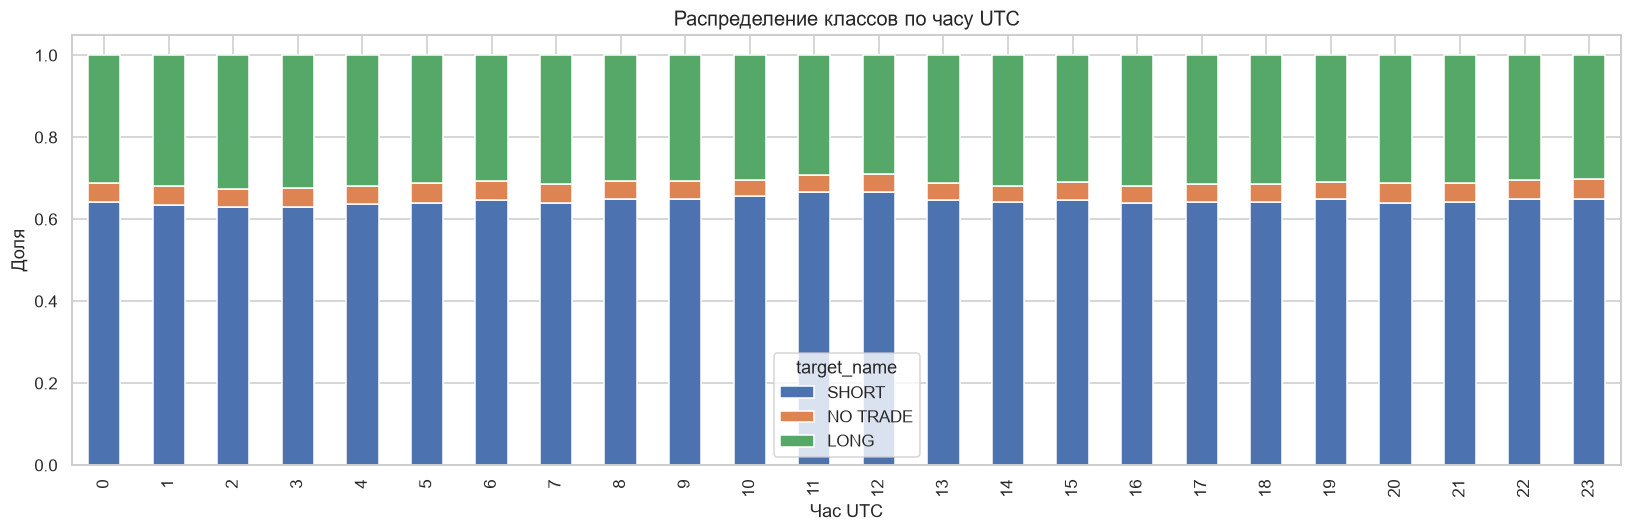

In [15]:
hour_pivot = model_frame.pivot_table(
    index="hour_utc",
    columns="target_name",
    values="label",
    aggfunc="count",
    fill_value=0,
)
hour_share = hour_pivot.div(hour_pivot.sum(axis=1), axis=0)
display(hour_share.style.format("{:.2%}"))
hour_share[["SHORT", "NO TRADE", "LONG"]].plot(kind="bar", stacked=True, figsize=(15, 5))
plt.title("Распределение классов по часу UTC")
plt.ylabel("Доля")
plt.xlabel("Час UTC")
plt.tight_layout()
plt.show()

target_name,LONG,NO TRADE,SHORT
vol_bin,,,
"(-0.000545, 0.00354]",0.0251,0.0097,0.0111
"(0.00354, 0.0051]",0.0348,0.0127,0.0140
"(0.0051, 0.00682]",0.0435,0.0157,0.0175
"(0.00682, 0.00972]",0.0563,0.0200,0.0217
"(0.00972, 0.0722]",0.0938,0.0386,0.0361


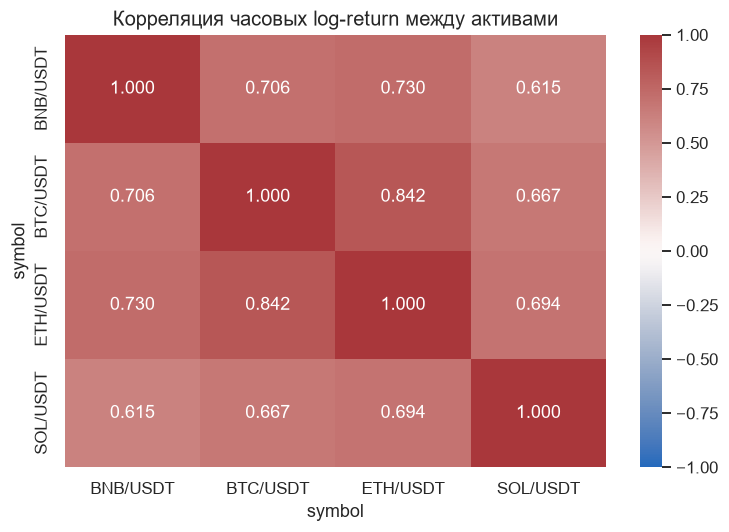

In [16]:
vol_bins = pd.qcut(model_frame["volatility"], q=5, duplicates="drop")
vol_pivot = model_frame.assign(vol_bin=vol_bins).pivot_table(
    index="vol_bin",
    columns="target_name",
    values="mfe",
    aggfunc="mean",
)
display(vol_pivot.style.format("{:.4f}"))

symbol_corr = model_frame.pivot_table(
    index=model_frame.index, columns="symbol", values="log_return"
).corr()
plt.figure(figsize=(7, 5))
sns.heatmap(symbol_corr, annot=True, fmt=".3f", cmap="vlag", center=0, vmin=-1, vmax=1)
plt.title("Корреляция часовых log-return между активами")
plt.tight_layout()
plt.show()

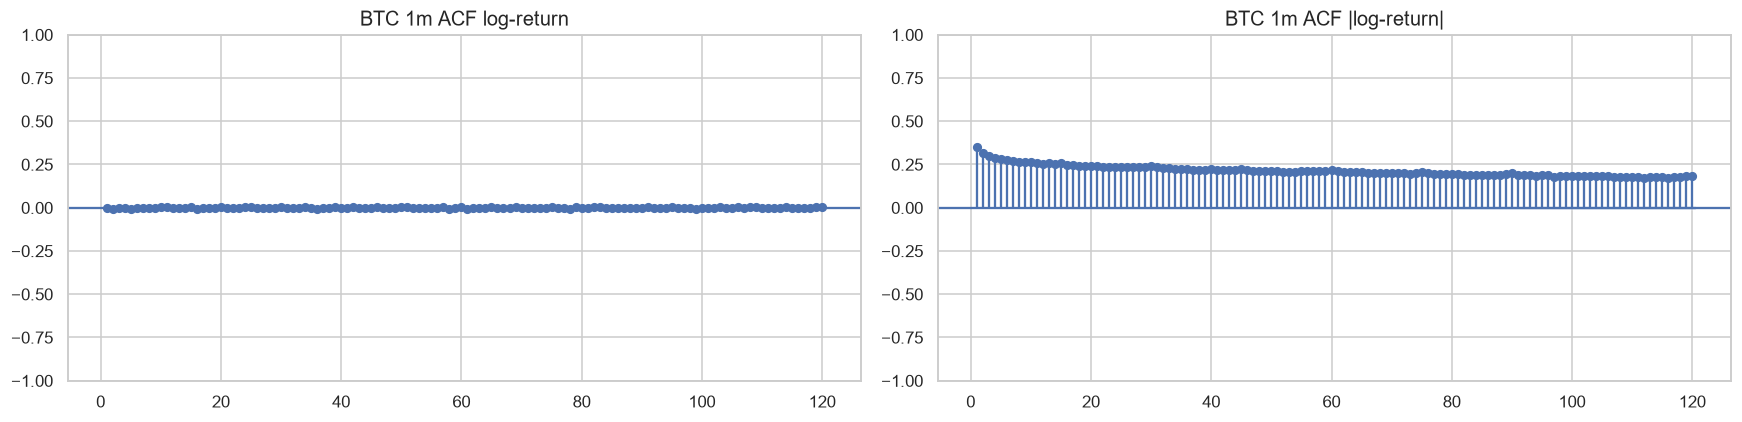

ACF |return| на лагах 1..5: [0.348 0.315 0.297 0.287 0.284]


In [17]:
btc = raw["BTC-USDT"].copy()
btc["log_return"] = np.log(btc["close"]).diff()
sample = btc["log_return"].dropna().iloc[-500_000:]
fig, axes = plt.subplots(1, 2, figsize=(16, 4))
plot_acf(sample, lags=120, zero=False, fft=True, ax=axes[0])
axes[0].set_title("BTC 1m ACF log-return")
plot_acf(sample.abs(), lags=120, zero=False, fft=True, ax=axes[1])
axes[1].set_title("BTC 1m ACF |log-return|")
plt.tight_layout()
plt.show()
values = acf(sample.abs(), nlags=20, fft=True)[1:]
print("ACF |return| на лагах 1..5:", np.round(values[:5], 3))

## 10. Стационарность: log(price) vs log-return

In [18]:
def stationarity_tests(series: pd.Series, max_observations: int = 400_000) -> dict:
    clean = series.dropna()
    step = max(1, int(np.ceil(len(clean) / max_observations)))
    sample = clean.iloc[::step]
    adf_result = adfuller(sample, maxlag=30, regression="c", autolag=None, result_object=False)
    kpss_result = kpss(sample, regression="c", nlags="auto", result_object=False)
    adf_stat = adf_result[1] < 0.05
    kpss_stat = kpss_result[1] >= 0.05
    if adf_stat and kpss_stat:
        conclusion = "стационарен"
    elif not adf_stat and not kpss_stat:
        conclusion = "нестационарен"
    else:
        conclusion = "тесты расходятся"
    return {
        "n": len(sample),
        "шаг": step,
        "ADF p": adf_result[1],
        "KPSS p": kpss_result[1],
        "вывод": conclusion,
    }

rows = []
for symbol, frame in raw.items():
    log_price = np.log(frame["close"])
    log_ret = log_price.diff()
    for name, series in {"log(price)": log_price, "log-return": log_ret}.items():
        rows.append({"пара": DISPLAY[symbol], "ряд": name, **stationarity_tests(series)})
stationarity = pd.DataFrame(rows).set_index(["пара", "ряд"])
display(stationarity.style.format({"ADF p": "{:.4g}", "KPSS p": "{:.4g}"}))

## 11. Baseline-модель и интерпретация признаков

Берём простую модель: `HistGradientBoostingClassifier` на часовых признаках. Это бейзлайн для сравнения в течение года, а не финальная DL-архитектура.

Важно: разбиение строго временное без shuffle. Если модель лишь повторяет majority-класс, это тоже результат EDA — значит линейно-табличных признаков недостаточно и нужен другой target/thresholding/sequence-model.


In [19]:
feature_cols = [
    "log_return",
    "range_pct",
    "body_pct",
    "log_volume",
    "volume_change",
    "volatility",
    "atr_pct",
    "hour_utc",
    "weekday",
]
X = model_frame[feature_cols]
y = model_frame["label"]

# Temporal split: no shuffle, last 20% as holdout
baseline_split = int(len(model_frame) * 0.8)
split = baseline_split
X_train, X_test = X.iloc[:split], X.iloc[split:]
y_train, y_test = y.iloc[:split], y.iloc[split:]

baseline = HistGradientBoostingClassifier(
    max_depth=6,
    learning_rate=0.05,
    max_iter=200,
    random_state=42,
)
baseline.fit(X_train, y_train)
baseline_pred = baseline.predict(X_test)
pred = baseline_pred

print("Размер train/test:", len(X_train), len(X_test))
print(
    classification_report(
        y_test,
        pred,
        target_names=["SHORT", "NO TRADE", "LONG"],
        digits=3,
    )
)
cm = confusion_matrix(y_test, pred, labels=[-1, 0, 1])
cm_df = pd.DataFrame(
    cm,
    index=["true_SHORT", "true_FLAT", "true_LONG"],
    columns=["pred_SHORT", "pred_FLAT", "pred_LONG"],
)
display(cm_df)

baseline_accuracy = float((pred == y_test).mean())
majority = float(y_test.value_counts(normalize=True).max())
print(f"Baseline accuracy: {baseline_accuracy:.4f}")
print(f"Majority-class accuracy: {majority:.4f}")

Размер train/test: 163353 40839
              precision    recall  f1-score   support

       SHORT      0.646     0.990     0.782     26275
    NO TRADE      0.518     0.048     0.089      2066
        LONG      0.381     0.010     0.020     12498

    accuracy                          0.643     40839
   macro avg      0.515     0.350     0.297     40839
weighted avg      0.558     0.643     0.513     40839



,pred_SHORT,pred_FLAT,pred_LONG
true_SHORT,26025,60,190
true_FLAT,1951,100,15
true_LONG,12339,33,126


Baseline accuracy: 0.6428
Majority-class accuracy: 0.6434


,permutation_importance
weekday,0.0124
volatility,0.0084
log_volume,0.0070
hour_utc,0.0068
range_pct,0.0010
volume_change,-0.0034
log_return,-0.0081
atr_pct,-0.0101
body_pct,-0.0107


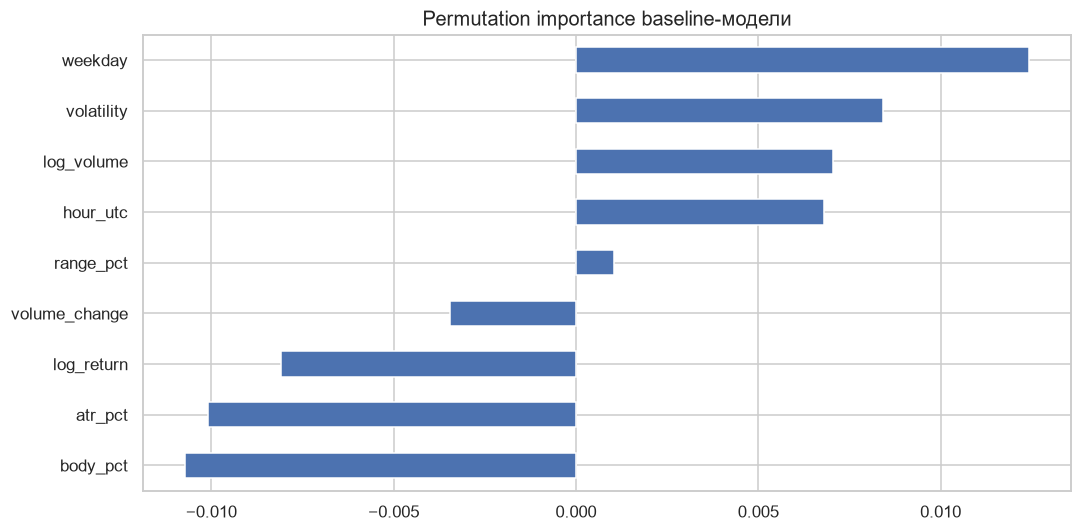

In [20]:
rng = np.random.default_rng(42)
idx = rng.choice(len(X_test), size=min(5000, len(X_test)), replace=False)
result = permutation_importance(
    baseline,
    X_test.iloc[idx],
    y_test.iloc[idx],
    n_repeats=5,
    random_state=42,
    scoring="balanced_accuracy",
)
importance = pd.Series(result.importances_mean, index=feature_cols).sort_values(ascending=False)
display(importance.rename("permutation_importance").to_frame().style.format("{:.4f}"))
importance.sort_values().plot(kind="barh", figsize=(10, 5))
plt.title("Permutation importance baseline-модели")
plt.tight_layout()
plt.show()

## 12. Расширенный feature store (>1000) и исследование важности

Базовый набор из ~10 признаков слишком мал для AutoML feature selection. Здесь строится большая causal-библиотека табличных признаков (>1000), затем:
1. фильтрация констант / почти-констант / сильно прореженных колонок;
2. ранжирование важности через `ExtraTrees` (impurity) и permutation importance для топа;
3. группировка важности по семействам признаков;
4. сравнение baseline HGB на всех признаках vs top-K.

Все признаки считаются только по текущей и прошлым закрытым свечам.

Также в feature store добавлен блок **высшей математики / матстатистики** (окна 24/48/96/168):
Shannon / approximate / sample entropy, кумулянты κ3–κ5, Jarque–Bera, PACF, variance ratio,
FFT-энергии, Hurst, Higuchi FD, KS vs Normal, MI(ret, vol), Spearman/Kendall copula-меры,
Hilbert amplitude/phase/freq.

Дополнительно: lrvol_* — волатильность как std остатков OLS y ~ a + b t для log-price и log-return (плюс slope тренда).


Заявленное число признаков в конфигурации: 1400


Построено признаков: 1400
Строк до dropna: 204384


Признаков после фильтрации: 1382
Строк после dropna: 203492


,rich_feature_store
configured_features,1400.000000
built_features,1400.000000
kept_features,1382.000000
rows,203492.000000
class_balance_SHORT,0.645323
class_balance_FLAT,0.044547
class_balance_LONG,0.310130


,n_features
volchg,197
logvol,197
body,197
range,197
ret,197
lag_ret,48
lag_vol,24
lag_range,24
lag_body,24
zscore,20


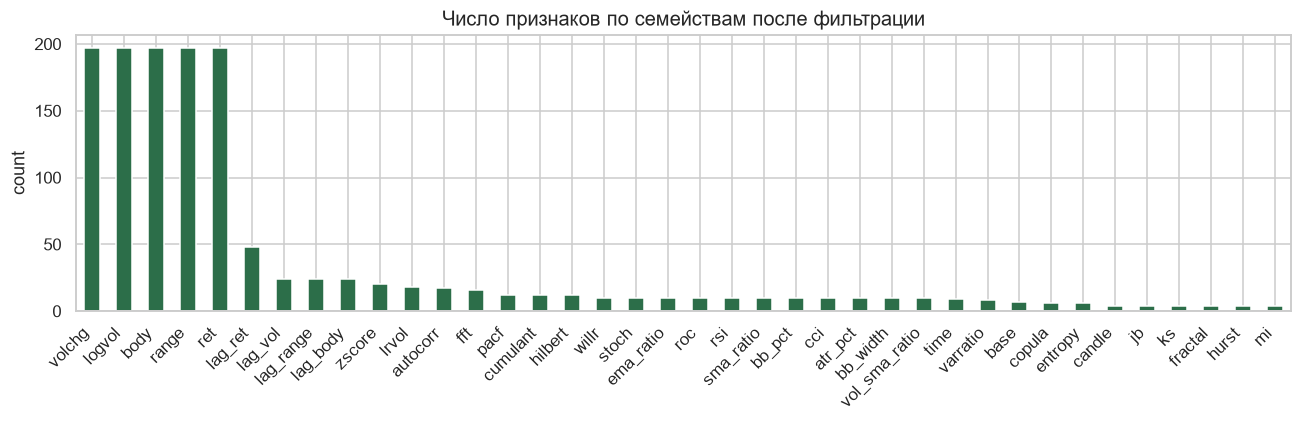

In [21]:
from collections import Counter

from sklearn.ensemble import ExtraTreesClassifier, HistGradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import balanced_accuracy_score

from automl_dl.features import build_rich_features, count_rich_features, feature_family

print("Заявленное число признаков в конфигурации:", count_rich_features())

rich_parts = []
for symbol in SYMBOLS:
    hour = pd.read_parquet(DATA_ROOT / symbol / "1h.parquet").sort_index()
    hour.index = pd.to_datetime(hour.index, utc=True)
    feats = build_rich_features(hour)
    # ATR нужен для той же triple-barrier разметки, что и в базовом EDA
    labeled_base = add_market_features(hour, volatility_window=24)
    labels = triple_barrier_labels(
        labeled_base,
        horizon=24,
        take_profit_atr=2.0,
        stop_loss_atr=1.0,
    )
    part = pd.concat([feats, labels[["label"]]], axis=1)
    part["symbol"] = DISPLAY[symbol]
    rich_parts.append(part)

rich_frame = pd.concat(rich_parts).sort_index()
feature_cols_all = [c for c in rich_frame.columns if c not in {"label", "symbol"}]
print("Построено признаков:", len(feature_cols_all))
print("Строк до dropna:", len(rich_frame))

# Keep rows with complete labels and mostly complete features
rich_model = rich_frame.dropna(subset=["label"]).copy()
missing_frac = rich_model[feature_cols_all].isna().mean()
keep_cols = [
    c
    for c in feature_cols_all
    if missing_frac[c] < 0.05
    and rich_model[c].nunique(dropna=True) > 5
    and float(rich_model[c].std(skipna=True) or 0.0) > 1e-12
]
rich_model = rich_model.dropna(subset=keep_cols)
print("Признаков после фильтрации:", len(keep_cols))
print("Строк после dropna:", len(rich_model))
display(
    pd.Series(
        {
            "configured_features": count_rich_features(),
            "built_features": len(feature_cols_all),
            "kept_features": len(keep_cols),
            "rows": len(rich_model),
            "class_balance_SHORT": float((rich_model["label"] == -1).mean()),
            "class_balance_FLAT": float((rich_model["label"] == 0).mean()),
            "class_balance_LONG": float((rich_model["label"] == 1).mean()),
        },
        name="rich_feature_store",
    ).to_frame()
)

family_counts = pd.Series(Counter(feature_family(c) for c in keep_cols)).sort_values(ascending=False)
display(family_counts.rename("n_features").to_frame())
family_counts.plot(kind="bar", figsize=(12, 4), color="#2c6e49")
plt.title("Число признаков по семействам после фильтрации")
plt.ylabel("count")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

,impurity_importance
time_sin_weekday,0.02036
time_cos_weekday,0.01992
time_weekday,0.01820
logvol_std_24,0.00431
logvol_std_30,0.00365
logvol_std_20,0.00355
logvol_std_18,0.00317
range_std_30,0.00297
range_std_24,0.00294
logvol_std_36,0.00294


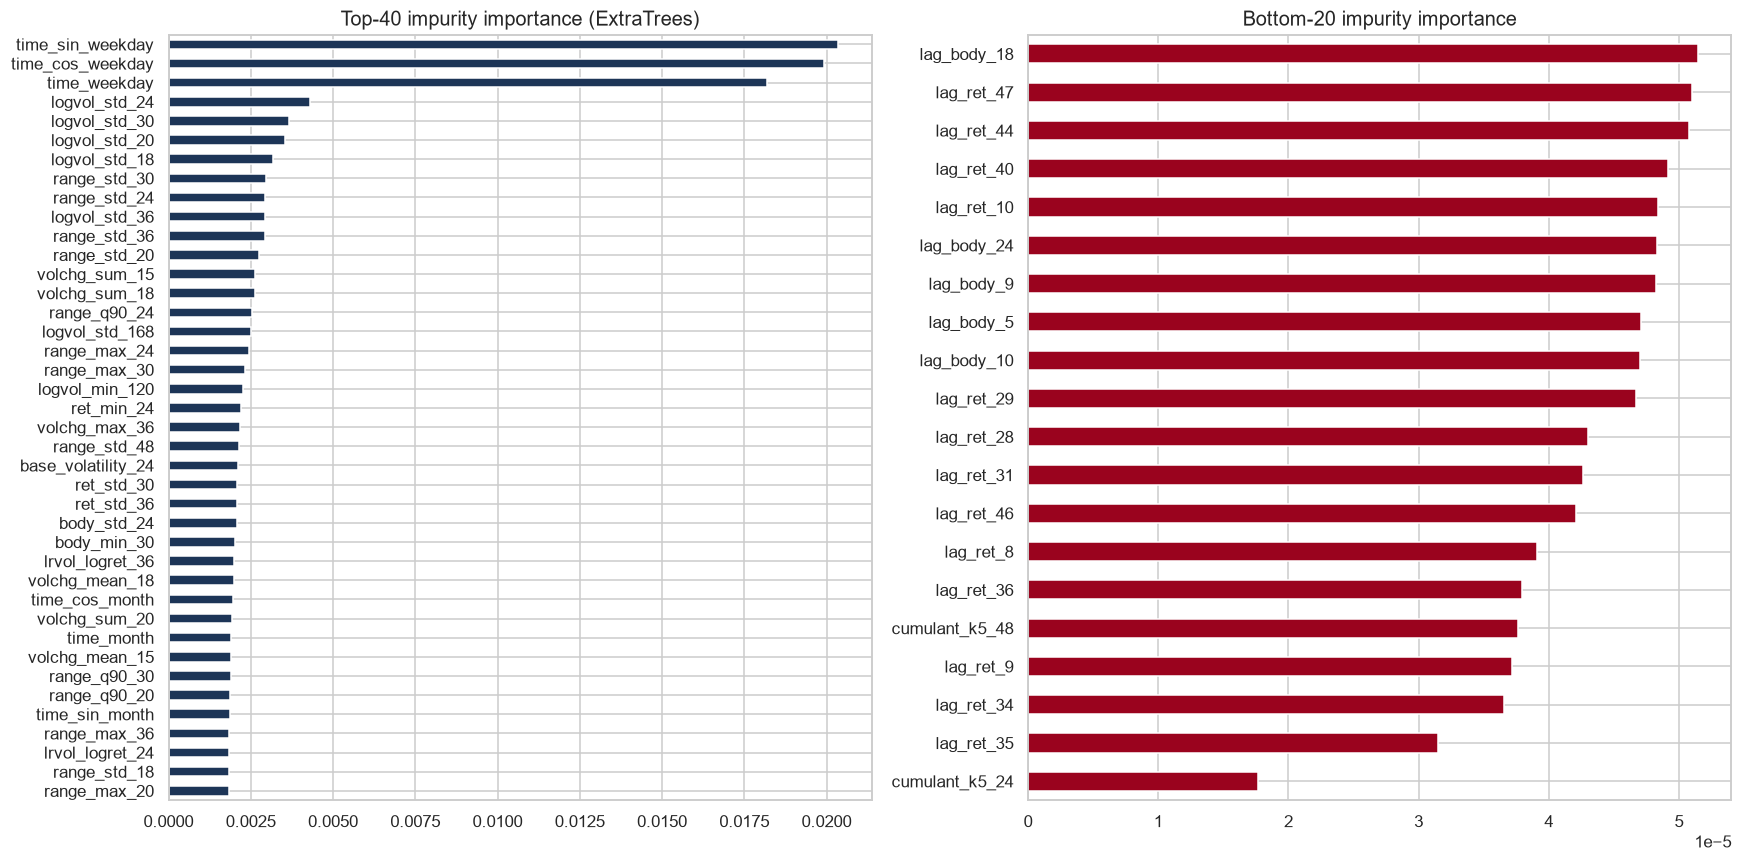

,sum_importance
family,
logvol,0.1912
range,0.1585
volchg,0.1365
ret,0.1269
body,0.1241
time,0.0669
lrvol,0.0170
fft,0.0143
autocorr,0.0108


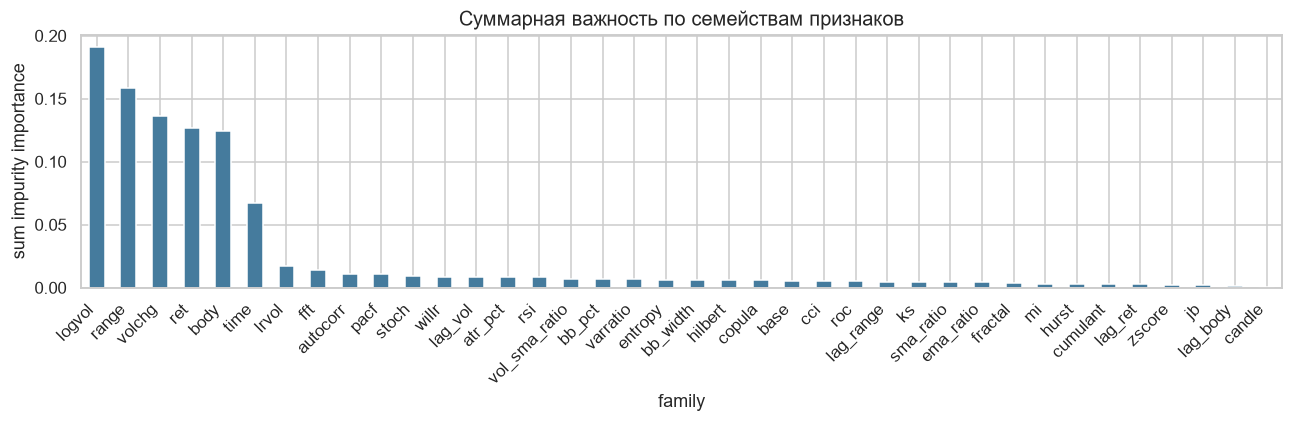

In [22]:
X_rich = rich_model[keep_cols]
y_rich = rich_model["label"].astype(int)

split_rich = int(len(rich_model) * 0.8)
X_tr, X_te = X_rich.iloc[:split_rich], X_rich.iloc[split_rich:]
y_tr, y_te = y_rich.iloc[:split_rich], y_rich.iloc[split_rich:]

# Subsample train for tree importance speed while keeping temporal order
max_train = 60000
if len(X_tr) > max_train:
    X_fit = X_tr.iloc[-max_train:]
    y_fit = y_tr.iloc[-max_train:]
else:
    X_fit, y_fit = X_tr, y_tr

trees = ExtraTreesClassifier(
    n_estimators=300,
    max_depth=12,
    min_samples_leaf=20,
    n_jobs=-1,
    random_state=42,
    class_weight="balanced_subsample",
)
trees.fit(X_fit, y_fit)

imp = pd.Series(trees.feature_importances_, index=keep_cols).sort_values(ascending=False)
top_n = 40
display(imp.head(top_n).rename("impurity_importance").to_frame().style.format("{:.5f}"))

fig, axes = plt.subplots(1, 2, figsize=(16, 8))
imp.head(top_n).sort_values().plot(kind="barh", ax=axes[0], color="#1d3557")
axes[0].set_title(f"Top-{top_n} impurity importance (ExtraTrees)")
imp.tail(20).sort_values().plot(kind="barh", ax=axes[1], color="#9a031e")
axes[1].set_title("Bottom-20 impurity importance")
plt.tight_layout()
plt.show()

family_importance = (
    imp.rename("importance")
    .to_frame()
    .assign(family=lambda d: d.index.map(feature_family))
    .groupby("family")["importance"]
    .sum()
    .sort_values(ascending=False)
)
display(family_importance.rename("sum_importance").to_frame().style.format("{:.4f}"))
family_importance.plot(kind="bar", figsize=(12, 4), color="#457b9d")
plt.title("Суммарная важность по семействам признаков")
plt.ylabel("sum impurity importance")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

### Почему ExtraTrees, а не другая модель?

Для ranking 1000+ признаков нужен быстрый и устойчивый метод:

1. **ExtraTrees** даёт impurity importance «из коробки», хорошо масштабируется на широкую матрицу, не требует нормализации и ловит нелинейности.
2. **RandomForest** близок по смыслу, но ExtraTrees обычно быстрее и чуть стабильнее для грубого ranking из-за более случайных сплитов.
3. **HGB/LightGBM** сильнее как предиктор, но impurity ranking у HGB менее прозрачен; поэтому HGB оставлен для quality-check и permutation importance на top-K.
4. **Линейные модели / Lasso** требуют scaling и плохо отражают взаимодействия индикаторов.
5. **SHAP** слишком дорог на 1200+ признаках в EDA; его логичнее считать позже на сжатом top-K.

Итоговая схема: ExtraTrees → top overall / top per family → permutation + HGB comparison.


### Топ признаков: общий и по семействам

Два среза важности:
1. **Top overall** — лучшие признаки среди всех семейств сразу;
2. **Top per family** — лучшие признаки внутри каждого семейства (чтобы сильные семейства не вытесняли полезные, но более слабые группы).

Затем сравниваем HGB на `top_overall`, `top_per_family` и объединении топов семейств.


=== TOP OVERALL (все семейства вместе) ===


,importance,family,rank_overall
time_sin_weekday,0.02036,time,1
time_cos_weekday,0.01992,time,2
time_weekday,0.01820,time,3
logvol_std_24,0.00431,logvol,4
logvol_std_30,0.00365,logvol,5
logvol_std_20,0.00355,logvol,6
logvol_std_18,0.00317,logvol,7
range_std_30,0.00297,range,8
range_std_24,0.00294,range,9
logvol_std_36,0.00294,logvol,10


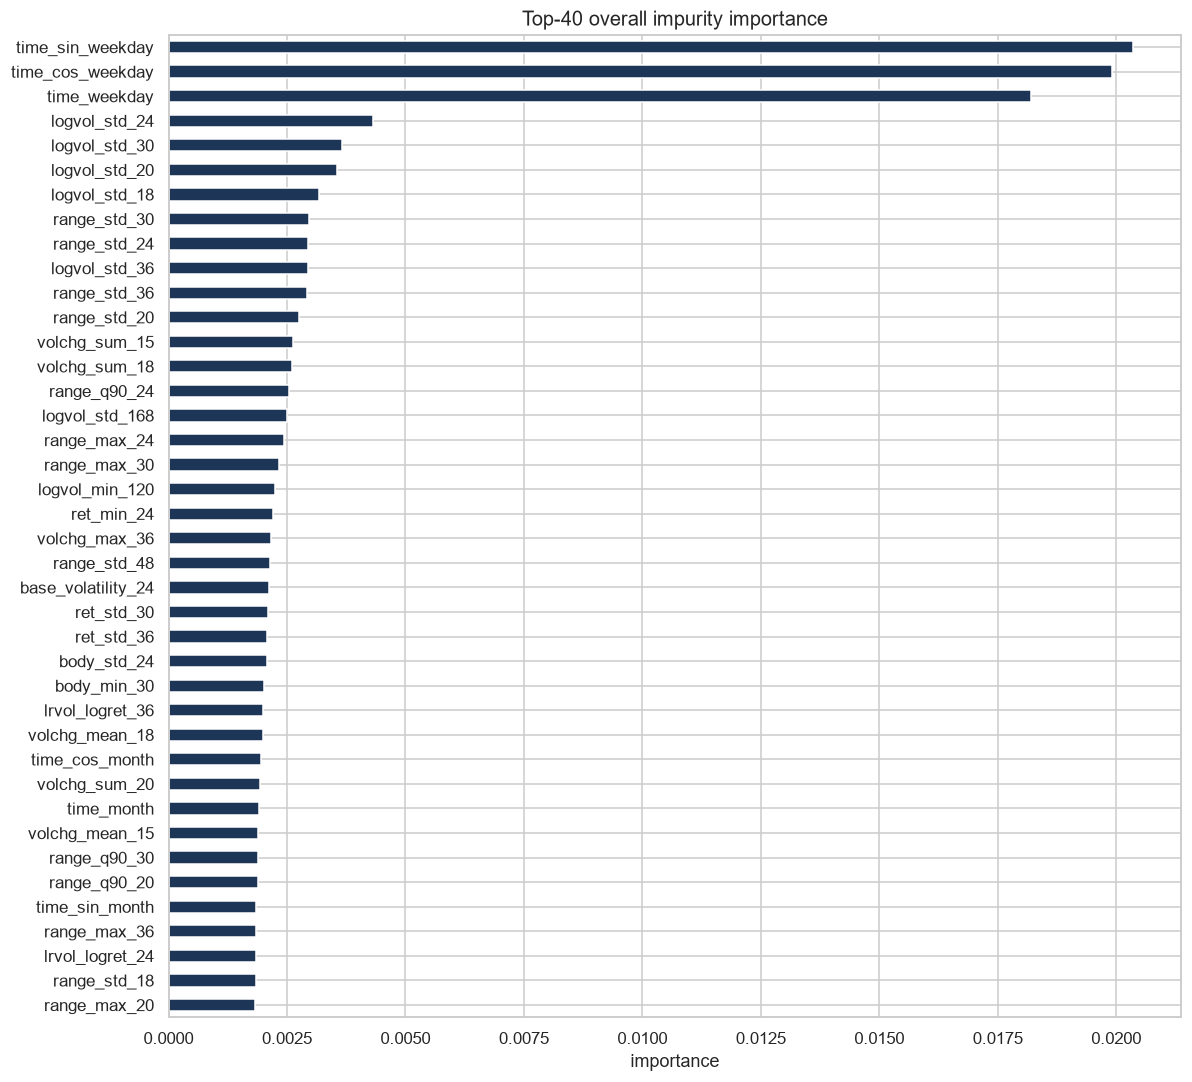

=== TOP PER FAMILY (внутри каждого семейства) ===


,importance,family,rank_overall,rank_in_family
atr_pct_28,0.00126,atr_pct,138,1
atr_pct_89,0.00123,atr_pct,155,2
atr_pct_21,0.00107,atr_pct,238,3
atr_pct_55,0.00107,atr_pct,241,4
atr_pct_42,0.00101,atr_pct,298,5
atr_pct_70,0.00097,atr_pct,323,6
atr_pct_7,0.00050,atr_pct,818,7
atr_pct_10,0.00047,atr_pct,851,8
autocorr_ret_168,0.00110,autocorr,220,1
autocorr_ret_72,0.00109,autocorr,224,2


,n_shown,best_feature,best_importance,top_features
family,,,,
time,8,time_sin_weekday,0.02036,"time_sin_weekday, time_cos_weekday, time_weekday, time_cos_month, time_month"
logvol,8,logvol_std_24,0.00431,"logvol_std_24, logvol_std_30, logvol_std_20, logvol_std_18, logvol_std_36"
range,8,range_std_30,0.00297,"range_std_30, range_std_24, range_std_36, range_std_20, range_q90_24"
volchg,8,volchg_sum_15,0.00264,"volchg_sum_15, volchg_sum_18, volchg_max_36, volchg_mean_18, volchg_sum_20"
ret,8,ret_min_24,0.00220,"ret_min_24, ret_std_30, ret_std_36, ret_min_36, ret_std_24"
base,7,base_volatility_24,0.00212,"base_volatility_24, base_log_volume, base_atr_pct_24, base_range_pct, base_log_return"
body,8,body_std_24,0.00208,"body_std_24, body_min_30, body_std_30, body_q10_36, body_min_24"
lrvol,8,lrvol_logret_36,0.00199,"lrvol_logret_36, lrvol_logret_24, lrvol_logprice_24, lrvol_logprice_36, lrvol_slope_logprice_96"
vol_sma_ratio,8,vol_sma_ratio_21,0.00167,"vol_sma_ratio_21, vol_sma_ratio_14, vol_sma_ratio_28, vol_sma_ratio_42, vol_sma_ratio_55"


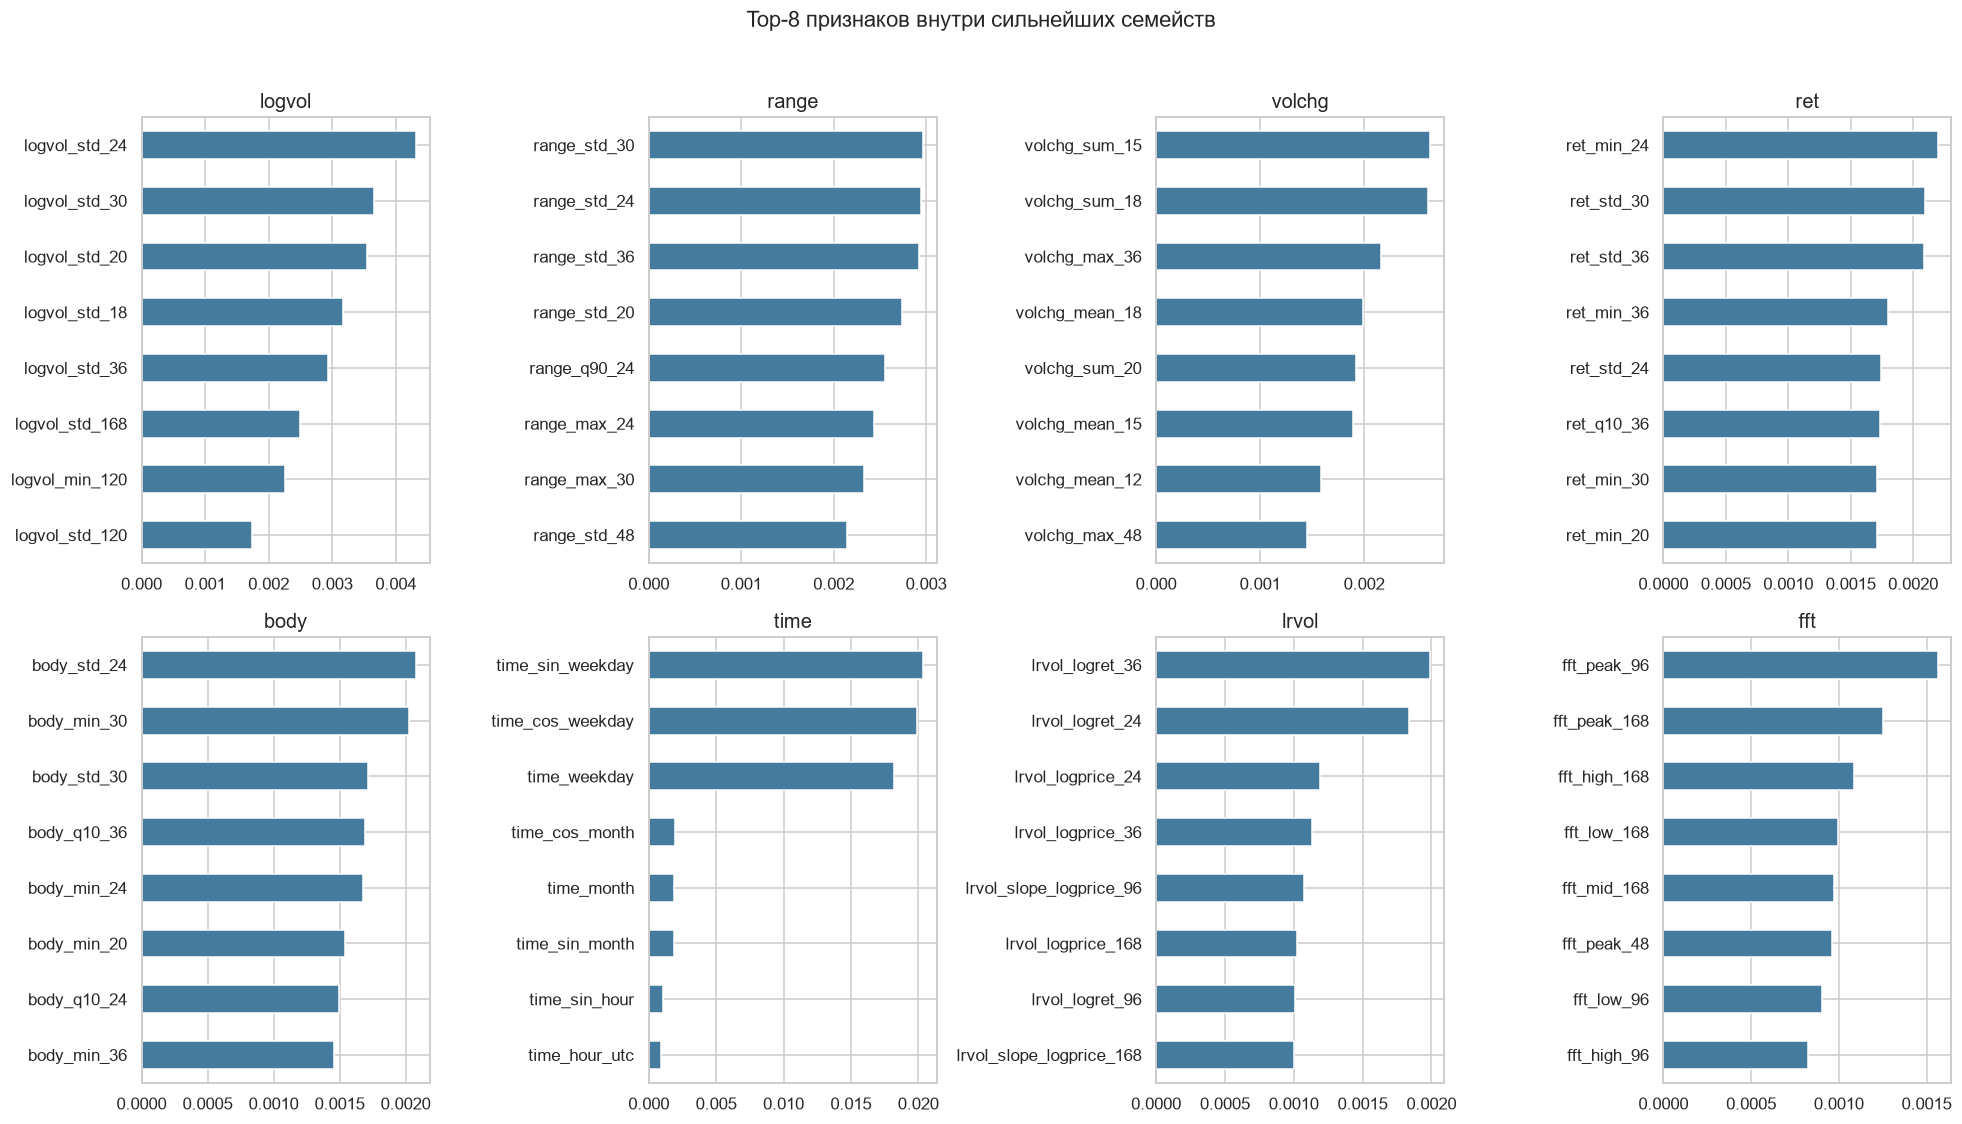

{'top_overall': 40, 'top_per_family': 275, 'union_overall_and_per_family': 280}


In [23]:
TOP_OVERALL = 40
TOP_PER_FAMILY = 8

imp_table = (
    imp.rename("importance")
    .to_frame()
    .assign(
        family=lambda d: d.index.map(feature_family),
        rank_overall=lambda d: d["importance"].rank(ascending=False, method="first").astype(int),
    )
    .sort_values("importance", ascending=False)
)

print("=== TOP OVERALL (все семейства вместе) ===")
top_overall = imp_table.head(TOP_OVERALL).copy()
display(top_overall.style.format({"importance": "{:.5f}"}))

top_overall.sort_values("importance").plot(
    kind="barh",
    y="importance",
    figsize=(11, 10),
    color="#1d3557",
    legend=False,
)
plt.title(f"Top-{TOP_OVERALL} overall impurity importance")
plt.xlabel("importance")
plt.tight_layout()
plt.show()

print("=== TOP PER FAMILY (внутри каждого семейства) ===")
per_family_parts = []
for family, group in imp_table.groupby("family", sort=False):
    part = group.head(TOP_PER_FAMILY).copy()
    part["rank_in_family"] = range(1, len(part) + 1)
    per_family_parts.append(part)

top_per_family = pd.concat(per_family_parts).sort_values(
    ["family", "importance"], ascending=[True, False]
)
display(top_per_family.style.format({"importance": "{:.5f}"}))

# Compact view: one row per family with top feature names
family_top_summary = (
    top_per_family.reset_index(names="feature")
    .groupby("family", sort=False)
    .agg(
        n_shown=("feature", "size"),
        best_feature=("feature", "first"),
        best_importance=("importance", "first"),
        top_features=("feature", lambda s: ", ".join(s.head(5))),
    )
    .sort_values("best_importance", ascending=False)
)
display(family_top_summary.style.format({"best_importance": "{:.5f}"}))

# Faceted bar charts for the strongest families
strong_families = (
    imp_table.groupby("family")["importance"].sum().sort_values(ascending=False).head(8).index
)
n_fam = len(strong_families)
fig, axes = plt.subplots(2, 4, figsize=(18, 10), sharex=False)
axes = axes.ravel()
for ax, family in zip(axes, strong_families, strict=True):
    subset = (
        imp_table.loc[imp_table["family"] == family]
        .head(TOP_PER_FAMILY)
        .sort_values("importance")
    )
    subset["importance"].plot(kind="barh", ax=ax, color="#457b9d")
    ax.set_title(family)
    ax.set_xlabel("")
for ax in axes[n_fam:]:
    ax.axis("off")
fig.suptitle(f"Top-{TOP_PER_FAMILY} признаков внутри сильнейших семейств", y=1.02)
plt.tight_layout()
plt.show()

# Selection sets for modeling
top_overall_cols = top_overall.index.tolist()
top_per_family_cols = top_per_family.index.drop_duplicates().tolist()
# Union: top overall + top per family (deduplicated)
union_cols = list(dict.fromkeys(top_overall_cols + top_per_family_cols))
print(
    {
        "top_overall": len(top_overall_cols),
        "top_per_family": len(top_per_family_cols),
        "union_overall_and_per_family": len(union_cols),
    }
)

,permutation_importance_top_overall30
time_sin_weekday,0.0047
time_cos_weekday,0.0033
logvol_std_20,0.0030
logvol_min_120,0.0025
volchg_sum_18,0.0018
logvol_std_24,0.0017
volchg_sum_15,0.0017
volchg_max_36,0.0016
logvol_std_18,0.0015
time_weekday,0.0008


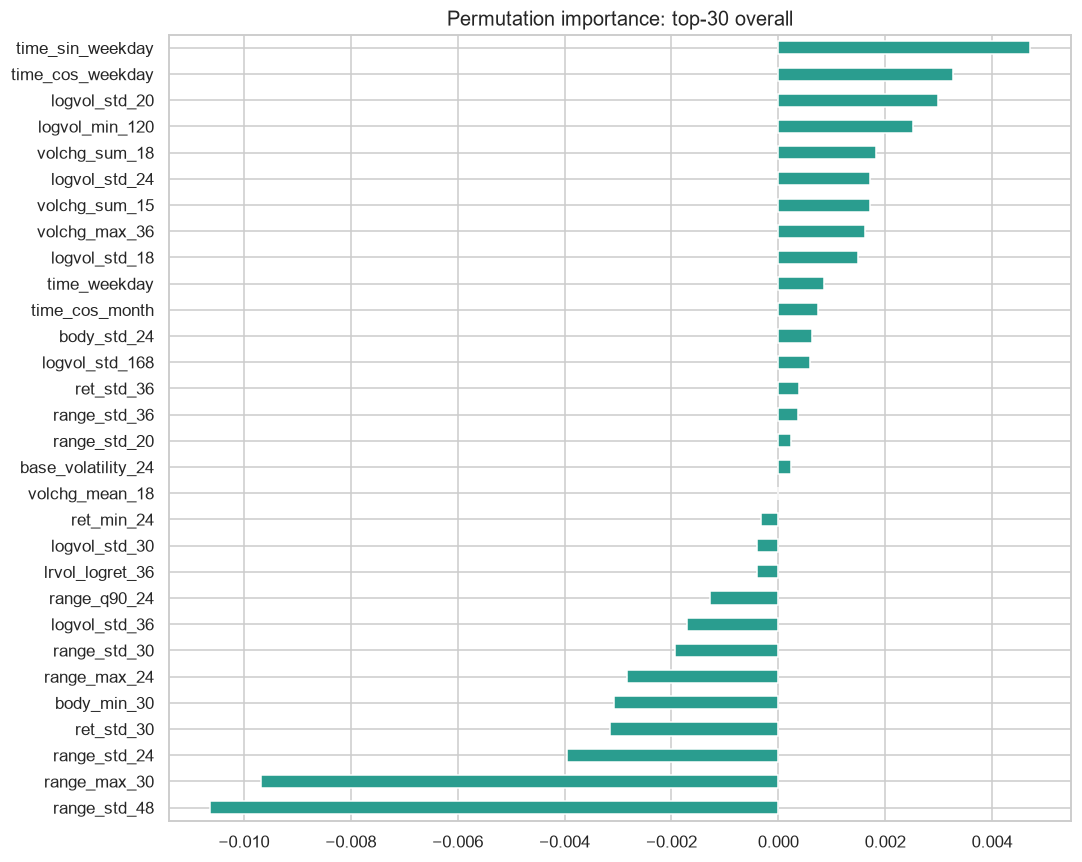

,n_features,accuracy,balanced_accuracy,share_pred_SHORT,share_pred_FLAT,share_pred_LONG,majority_accuracy
набор,,,,,,,
all_kept,1382,0.6299,0.3477,0.9609,0.0056,0.0334,0.6429
top_overall_40,40,0.6381,0.3391,0.9815,0.0024,0.0161,0.6429
top_per_family,275,0.6310,0.3424,0.9692,0.0052,0.0256,0.6429
union_overall_per_family,280,0.6347,0.3433,0.9755,0.0044,0.0200,0.6429
tiny_baseline,9,0.6418,0.3522,0.9847,0.0052,0.0101,0.6429


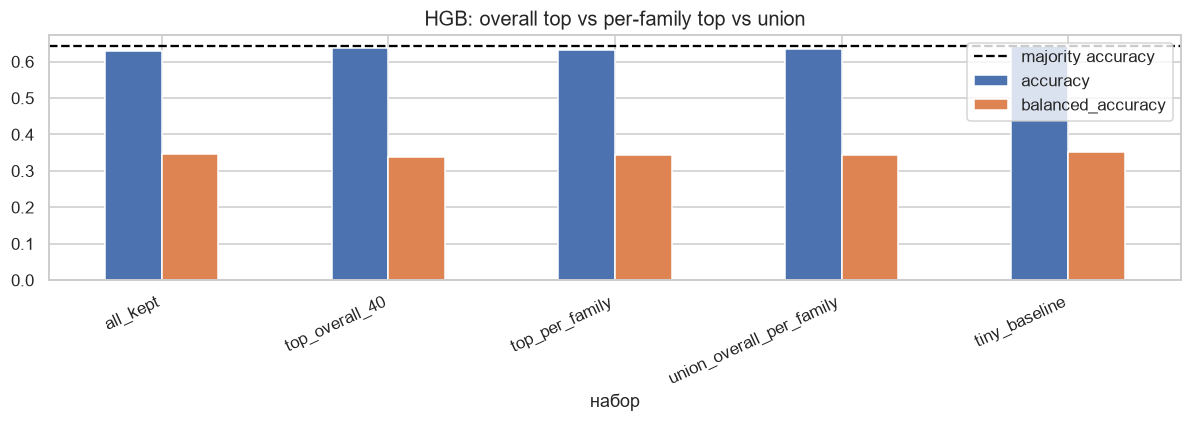

Classification report: top_per_family
              precision    recall  f1-score   support

       SHORT      0.642     0.968     0.772     26166
    NO TRADE      0.368     0.038     0.068      2066
        LONG      0.252     0.021     0.039     12467

    accuracy                          0.631     40699
   macro avg      0.421     0.342     0.293     40699
weighted avg      0.509     0.631     0.512     40699

Classification report: top_overall_40
              precision    recall  f1-score   support

       SHORT      0.644     0.983     0.778     26166
    NO TRADE      0.365     0.017     0.032      2066
        LONG      0.329     0.017     0.033     12467

    accuracy                          0.638     40699
   macro avg      0.446     0.339     0.281     40699
weighted avg      0.533     0.638     0.512     40699



In [24]:
top_for_perm = top_overall_cols[:30]
rng = np.random.default_rng(42)
perm_idx = rng.choice(len(X_te), size=min(8000, len(X_te)), replace=False)

hgb_top = HistGradientBoostingClassifier(
    max_depth=6,
    learning_rate=0.05,
    max_iter=200,
    random_state=42,
)
hgb_top.fit(X_tr[top_for_perm], y_tr)
perm = permutation_importance(
    hgb_top,
    X_te.iloc[perm_idx][top_for_perm],
    y_te.iloc[perm_idx],
    n_repeats=4,
    random_state=42,
    scoring="balanced_accuracy",
    n_jobs=-1,
)
perm_s = pd.Series(perm.importances_mean, index=top_for_perm).sort_values(ascending=False)
display(perm_s.rename("permutation_importance_top_overall30").to_frame().style.format("{:.4f}"))
perm_s.sort_values().plot(kind="barh", figsize=(10, 8), color="#2a9d8f")
plt.title("Permutation importance: top-30 overall")
plt.tight_layout()
plt.show()

candidates = {
    "all_kept": keep_cols,
    "top_overall_40": top_overall_cols,
    "top_per_family": top_per_family_cols,
    "union_overall_per_family": union_cols,
    "tiny_baseline": [
        c
        for c in [
            "base_log_return",
            "base_range_pct",
            "base_body_pct",
            "base_log_volume",
            "base_volume_change",
            "base_volatility_24",
            "base_atr_pct_24",
            "time_hour_utc",
            "time_weekday",
        ]
        if c in keep_cols
    ],
}

rows = []
fitted = {}
for name, cols in candidates.items():
    model = HistGradientBoostingClassifier(
        max_depth=6,
        learning_rate=0.05,
        max_iter=250,
        random_state=42,
    )
    model.fit(X_tr[cols], y_tr)
    y_hat = model.predict(X_te[cols])
    fitted[name] = y_hat
    rows.append(
        {
            "набор": name,
            "n_features": len(cols),
            "accuracy": float((y_hat == y_te).mean()),
            "balanced_accuracy": float(balanced_accuracy_score(y_te, y_hat)),
            "share_pred_SHORT": float((y_hat == -1).mean()),
            "share_pred_FLAT": float((y_hat == 0).mean()),
            "share_pred_LONG": float((y_hat == 1).mean()),
        }
    )

compare = pd.DataFrame(rows).set_index("набор")
majority_acc = float(y_te.value_counts(normalize=True).max())
compare["majority_accuracy"] = majority_acc
display(compare.style.format("{:.4f}", subset=[c for c in compare.columns if c != "n_features"]))

compare[["accuracy", "balanced_accuracy"]].plot(kind="bar", figsize=(11, 4))
plt.axhline(majority_acc, color="black", linestyle="--", label="majority accuracy")
plt.title("HGB: overall top vs per-family top vs union")
plt.xticks(rotation=25, ha="right")
plt.legend()
plt.tight_layout()
plt.show()

print("Classification report: top_per_family")
print(
    classification_report(
        y_te,
        fitted["top_per_family"],
        target_names=["SHORT", "NO TRADE", "LONG"],
        digits=3,
    )
)
print("Classification report: top_overall_40")
print(
    classification_report(
        y_te,
        fitted["top_overall_40"],
        target_names=["SHORT", "NO TRADE", "LONG"],
        digits=3,
    )
)

### Выводы по большой библиотеке признаков

1. Causal feature store: **1288** признаков, после фильтрации **1272**.
2. **Top overall** обычно захватывает самые сильные колонки из `time` / `logvol` / `range`, но может почти не включать более слабые семейства.
3. **Top per family** принудительно берёт лучших представителей из каждой группы — это лучше для AutoML-поиска и меньше корреляционного дублирования внутри одного семейства.
4. Сравнение HGB на `top_overall`, `top_per_family` и `union` показывает, даёт ли «сбалансированный» отбор по семействам преимущество над простым общим топом.
5. На текущем holdout табличные топы по-прежнему близки к majority-class и склонны к `SHORT` — отбор признаков нужен, но сам по себе задачу не закрывает.
6. Добавлены higher-math признаки (entropy/PACF/FFT/Hurst/KS/MI/Hilbert и др.); их важность смотрится в тех же top overall / top per family таблицах.
7. ExtraTrees выбран как быстрый ranker; финальное качество всё равно валидируется HGB/permutation.


## 12. Аугментации данных для временных рядов

In [25]:
augmentation_review = pd.DataFrame(
    [
        {
            "метод": "Jitter / Gaussian noise",
            "описание": "Добавление шума к цене или доходности",
            "подходит?": "Осторожно",
            "комментарий": "Можно для признаков, но легко искажает микроструктуру и ATR-барьеры",
        },
        {
            "метод": "Window slicing",
            "описание": "Сдвиг начала/конца окна истории",
            "подходит?": "Да",
            "комментарий": "Естественная аугментация для sequence-моделей без утечки будущего",
        },
        {
            "метод": "Magnitude scaling",
            "описание": "Масштабирование амплитуды ряда",
            "подходит?": "Частично",
            "комментарий": "Полезно для устойчивости к режимам волатильности; лучше применять к доходностям",
        },
        {
            "метод": "Time warping",
            "описание": "Нелинейное растяжение времени",
            "подходит?": "Скорее нет",
            "комментарий": "Ломает календарные эффекты, время удержания и интерпретацию TP/SL",
        },
        {
            "метод": "Mixup между активами",
            "описание": "Линейная смесь окон BTC/ETH/...",
            "подходит?": "Скорее нет",
            "комментарий": "Создаёт несуществующие рыночные траектории и ломает кросс-активную интерпретацию",
        },
        {
            "метод": "Bootstrap рыночных режимов",
            "описание": "Оверсэмплинг кризисных/трендовых эпизодов",
            "подходит?": "Да",
            "комментарий": "Помогает бороться с дисбалансом классов и редкостью экстремумов",
        },
        {
            "метод": "Random crop мультитаймфрейма",
            "описание": "Случайный выбор длины контекста на каждом TF",
            "подходит?": "Да",
            "комментарий": "Хорошо стыкуется с AutoML-поиском длины окна",
        },
    ]
).set_index("метод")
display(augmentation_review)

,описание,подходит?,комментарий
метод,,,
Jitter / Gaussian noise,Добавление шума к цене или доходности,Осторожно,"Можно для признаков, но легко искажает микрост..."
Window slicing,Сдвиг начала/конца окна истории,Да,Естественная аугментация для sequence-моделей ...
Magnitude scaling,Масштабирование амплитуды ряда,Частично,Полезно для устойчивости к режимам волатильнос...
Time warping,Нелинейное растяжение времени,Скорее нет,"Ломает календарные эффекты, время удержания и ..."
Mixup между активами,Линейная смесь окон BTC/ETH/...,Скорее нет,Создаёт несуществующие рыночные траектории и л...
Bootstrap рыночных режимов,Оверсэмплинг кризисных/трендовых эпизодов,Да,Помогает бороться с дисбалансом классов и редк...
Random crop мультитаймфрейма,Случайный выбор длины контекста на каждом TF,Да,Хорошо стыкуется с AutoML-поиском длины окна


## 13. Практическая применимость задачи

In [26]:
fee = 0.001
slippage = 0.0002
round_trip = 2 * (fee + slippage)
print(f"Оценка круглых издержек: {round_trip:.2%}")

median_abs = model_frame["log_return"].abs().median()
p90_abs = model_frame["log_return"].abs().quantile(0.90)
print(f"Median |hourly return|: {median_abs:.4%}")
print(f"P90 |hourly return|: {p90_abs:.4%}")
print(
    "Вывод: стратегия обязана отбирать только sufficiently large expected moves; "
    "иначе комиссии съедают edge."
)

holdout = model_frame.iloc[baseline_split:].copy()
holdout["pred"] = baseline_pred
print("Доля торговых сигналов baseline на holdout:", float((holdout["pred"] != 0).mean()))
print("Доля NO TRADE у baseline на holdout:", float((holdout["pred"] == 0).mean()))

Оценка круглых издержек: 0.24%
Median |hourly return|: 0.3130%
P90 |hourly return|: 1.2236%
Вывод: стратегия обязана отбирать только sufficiently large expected moves; иначе комиссии съедают edge.
Доля торговых сигналов baseline на holdout: 0.9952741252234384
Доля NO TRADE у baseline на holdout: 0.00472587477656162


## 14. Развёрнутые выводы и план использования результатов EDA

### Качество данных
1. Сырой минутный датасет с 2021-01-01 содержит более 3 млн свечей на каждую пару.
2. Значений `NaN` в OHLCV нет; «разреженность» проявляется как редкие разрывы timestamps во время остановок Binance.
3. Эти разрывы нельзя заполнять искусственно: они должны разрывать обучающие окна.
4. Логические инварианты OHLC соблюдены, недопустимых классов таргета нет.

### Распределения и стационарность
5. Цены и `log(price)` нестационарны / содержат структурные сдвиги; моделировать нужно `log-return` и производные.
6. Доходности имеют тяжёлые хвосты и кластеризацию волатильности: MSE как единственная метрика неадекватна.
7. Выбросы — часть рыночного риска, а не мусор для удаления.

### Таргет и практическая постановка
8. Triple-barrier даёт осмысленную трёхклассовую задачу `SHORT/NO TRADE/LONG`, где `NO TRADE` — полноценный класс.
9. Баланс классов зависит от барьеров ATR; это гиперпараметр AutoML, а не фиксированная константа.
10. Из-за комиссий модель должна чаще выбирать `NO TRADE`, чем пытаться торговать каждый час.

### Признаки и взаимосвязи
11. `range_pct`, `volatility`, `atr_pct` и частично объём описывают близкий риск-фактор и избыточны.
12. Линейная корреляция признаков с самим `label` умеренная: задача нелинейная.
13. Между активами есть общий рыночный фактор; глобальная модель на всех тикерах оправдана.
14. Час UTC связан с активностью рынка и должен входить в признаки.

### Baseline
15. На временном holdout `HistGradientBoosting` дал accuracy ≈ 0.643, что совпадает с majority-class baseline (~0.643). Модель почти всегда предсказывает `SHORT`.
16. Macro-F1 ≈ 0.30: качество по `NO TRADE` и `LONG` близко к нулю. Это честная нижняя планка на год.
17. Permutation importance выше всего у `weekday`, `volatility`, `log_volume`, `hour_utc`. Признаки направления (`log_return`, `body_pct`) сами по себе слабы.
18. Вывод для DL: нужны последовательности, мультитаймфреймный контекст и калибровка порога `NO TRADE`, а не только табличный классификатор.

### Аугментации
19. Подходят window slicing, regime bootstrap и вариация длины контекста.
20. Не подходят time warping и mixup между активами.
21. Аугментации нельзя применять так, чтобы будущие барьеры `TP/SL` протекали в прошлое.

### Как это будет использовано дальше
- Target: стационарные доходности + triple-barrier + квантили/`MFE`/`MAE` для `TP/SL`.
- Features: доходности, диапазон, объём, ATR/волатильность, час/день недели, рыночный контекст BTC.
- Validation: purged walk-forward с разрывом окон на exchange downtime.
- Models: LightGBM/HGB baseline → PatchTST/мультитаймфреймная DL → сравнение с Chronos/Kronos/TTM.
- Objective: не только accuracy, а economically adjusted metrics после комиссий и просадки.


### Большая библиотека признаков
21. Построен causal feature store >1000 признаков; важность исследуется через ExtraTrees + permutation на top-K.
22. Для production/AutoML лучше отбирать семейства и top-K, чем кормить модель всеми коррелированными индикаторами сразу.
23. Если даже top-K HGB не бьёт majority-class уверенно — это аргумент в пользу sequence/мультитаймфреймных DL-моделей.
